# Attribute explainability

**Why this notebook.** The attribute models do not beat MSP on AUROC, but MSP cannot say *why* a
prediction is likely wrong. Attributes can: they are named, per-organ image measurements
(area, intensity, shape...). And because every image is paired with a **counterfactual** (its
nearest image from the other class), each attribute can be read three ways: the image's value,
the counterfactual's value, and the difference between them. The goal is to find the few
attributes that best separate C0's correct from incorrect calls, and show them as
**image vs counterfactual** profiles. This redoes `notebooks/cf_attribute_analysis.ipynb` on the
final, patient-disjoint split.

**Where this sits in the pipeline.**

```
image x  ──►  C0  ──►  prediction (positive / negative, probability p)
                 │
                 └──►  C2 (attribute model, I+C+D)  ──►  quality score = P(C0's call is correct)
                                                            │
                                   this notebook  ──►  why that score: which group of images x
                                                        belongs to, that group's track record,
                                                        and how x differs from its counterfactual
```

MSP and C2 both give a number; this notebook turns C2's number into a reason. Every figure is
conditional on C0's call, as C2's score is, and the case cards put the three together: C0's call,
C2's quality score, and the explanation.

**C2's score is shown as a percentile, not a probability.** C2 was trained with class-balanced
weights, so its raw output is a ranking score, not a calibrated P(correct). It is reported as its
percentile among the calls of the same kind ("lower than 82% of C0's positive calls").

**Steps**
1. Pick the attribute model to explain (I+C+D) and load its out-of-fold scores.
2. Load each image's attributes, its nearest counterfactual's attributes, and the deltas.
3. Split by C0's prediction, and within each side correlate every attribute, in all three
   forms (image, CF, delta), with correctness: TP vs FP / TN vs FN.
4. Keep the top non-redundant attributes per side.
5. Dumbbell profiles per quadrant: image (filled dot) vs counterfactual (hollow dot).
6. Cluster the images on the hidden layer of the C2 MLP, a space organised by correctness
   itself, give each group's error rate, and describe each group afterwards by its attribute
   profile.
   **6b.** The same clustering in four spaces (attributes, delta, attributes + delta, C2
   embedding), each on its own t-SNE map coloured by where C0 is wrong: which information
   separates C0's errors?
7. Case cards: one image, its counterfactual, its group, and why it belongs there.

The groups are *described* by attributes only, because those are named measurements. The C2
embedding they are *found* in also sees C0's image embeddings (see step 6), so a group can rest on
things no attribute measures.

**Running it for another disease or CF source**: set `DISEASE` / `SOURCE` / `K_VALUES` in the
setup cell (diffusion: `SOURCE = "diffusion_hml_sub20k"`, `K_VALUES = [1]`), then **restart the
kernel and run all**: several cells keep caches that would otherwise belong to the previous run.

**Figures** follow the thesis style (`code/thesis_style.py`, as in `C2_evaluation.ipynb`): drawn at Nature column width, so fonts and lines are their printed sizes. Set `SAVE_FIGS = True` in the setup cell to also write each figure as PDF + PNG to `figures/xai/<disease>/`.

In [ ]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
import torch, torchxrayvision as xrv
from PIL import Image
from matplotlib.colors import to_rgba
from matplotlib.patches import Patch
import gc

sys.path.insert(0, os.path.abspath("code"))
from c2_folds import load_folds
from c2_cf_sources import build_cf_source

# effusion | atelectasis | cardiomegaly | consolidation | edema. XAI_DISEASE overrides it, so the
# whole notebook can be run per disease from the shell (XAI_DISEASE=edema jupyter nbconvert --execute ...).
DISEASE = os.environ.get("XAI_DISEASE", "effusion")
SOURCE  = "knn_correct_cf"     # or "diffusion_hml_sub20k"
K_VALUES = [10]               # knn: [10] | diffusion: [1]
print(DISEASE, SOURCE, K_VALUES)

RESULTS = os.environ.get("THESIS_RESULTS", "/work3/s251710/thesis_results")
C2      = os.path.join(RESULTS, "C2_final_results")

# Thesis-wide style, as in C2_evaluation: figures are drawn at print size (FULL / HALF are the
# Nature column widths, MM converts millimetres), so the fonts and line widths are the printed ones.
import importlib, thesis_style
importlib.reload(thesis_style)     # pick up edits to the style file without a kernel restart
from thesis_style import *
apply()

# Every figure is also written to FIG_DIR, as in C2_evaluation (figures/c2): PDF is vector (use it
# in \includegraphics), PNG for slides and quick looks. One folder per disease under figures/xai,
# and the disease + CF source in every file name, so runs for other diseases never overwrite.
SAVE_FIGS   = True
FIG_DIR     = os.path.join("figures", "xai", DISEASE)
FIG_FORMATS = ("pdf", "png")

def fig_path(name, ext):
    return os.path.join(FIG_DIR, f"{DISEASE}_{SOURCE}_{name}.{ext}")

def save(fig, name):
    """Write `fig` as FIG_DIR/<disease>_<source>_<name>.{pdf,png}."""
    if SAVE_FIGS:
        os.makedirs(FIG_DIR, exist_ok=True)
        for ext in FIG_FORMATS:
            fig.savefig(fig_path(name, ext))

def save_text(name, text):
    """Write a figure's caption / details as FIG_DIR/<disease>_<source>_<name>.txt, beside it."""
    if SAVE_FIGS:
        os.makedirs(FIG_DIR, exist_ok=True)
        with open(fig_path(name, "txt"), "w", encoding="utf-8") as f:
            f.write(text.rstrip() + "\n")

effusion diffusion_hml_sub20k [1]


## 1. Best attribute model

Reads `cv_summary.csv` of the block-ablation runs (`c2_train_attributes.py`, the patient-grouped
rerun of 2026-09-27) for every K. Always explains the complete model, I+C+D (query, counterfactual and delta blocks), so the deltas analysed below are real model inputs. K is picked as the best for that config. The overall best config is printed next to it: for effusion, I+C is 0.0007 AUROC higher, well within the fold standard deviation.

In [4]:
CONFIG   = "I+C+D"   # always the complete model: query, counterfactual and delta blocks

summaries = []
for k in K_VALUES:
    s = pd.read_csv(os.path.join(C2, DISEASE, SOURCE, f"cf_{k}", "attributes", "cv_summary.csv"))
    summaries.append(s[s["model"] == "MLP"].assign(K=k))
summaries = pd.concat(summaries).sort_values("auc_mean", ascending=False)
display(summaries[["K", "config", "auc_mean", "auc_std"]].head(5))   # overall best, for reference

# Best K for the complete model
best = summaries[summaries["config"] == CONFIG].iloc[0]
BEST_K, BEST_CONFIG = int(best["K"]), CONFIG
overall = summaries.iloc[0]
print(f"explaining: {BEST_CONFIG} at K={BEST_K}  (AUROC {best['auc_mean']:.4f} ± {best['auc_std']:.4f})")
print(f"overall best: {overall['config']} at K={int(overall['K'])}  (AUROC {overall['auc_mean']:.4f})")

# Out-of-fold predictions of that model: one row per query, pooled over the 5 folds.
pred_dir = os.path.join(C2, DISEASE, SOURCE, f"cf_{BEST_K}", "attributes")
model_scores = pd.concat(
    [pd.read_csv(os.path.join(pred_dir, f"fold_{i}_predictions.csv"),
                 usecols=["path", f"MLP_{BEST_CONFIG}_prob"]) for i in range(5)])
model_scores = model_scores.rename(columns={f"MLP_{BEST_CONFIG}_prob": "model_score"})

,K,config,auc_mean,auc_std
0,1,I+C,0.774296,0.010125
1,1,I+C+D,0.771747,0.012643
2,1,I,0.769724,0.005240
3,1,D,0.754448,0.008062
4,1,C,0.699756,0.008514


explaining: I+C+D at K=1  (AUROC 0.7717 ± 0.0126)
overall best: I+C at K=1  (AUROC 0.7743)


## 2. Attributes, counterfactual attributes and deltas

Each query sits in the test side of exactly one fold, so pooling the five test sides gives
every image once. Per image we keep, for each of the 461 attributes (`fold.ctx.rel`):

* `<attr>`: the image's own value
* `cf_attr_<attr>`: the value of its **nearest** counterfactual, a real image from the other class
* `delta_<attr>`: image minus counterfactual, in the fold's standardised units (the model's input)

plus C0's probability for the image and for its counterfactual, and the counterfactual's path
(to show it on the case cards).

Two things to keep in mind:
* The model at K>1 averages its score over K counterfactuals, but here only the nearest one is
  used (slot 0). The pairing is nearest-first, so slot 0 is the same at every K.
* Loading takes a few minutes and ~7 GB: `c2_data.csv` is read once, then each fold is built.

In [5]:
if SOURCE == "diffusion_hml_sub20k":
    src = build_cf_source("diffusion", subset="20k")
else:
    src = build_cf_source("knn", strategy="correct_cf")

assert src.name == SOURCE

parts = []
for fold in load_folds(DISEASE, src, cf_count=1):
    df = fold.test_slot(0)                       # each image paired with its nearest CF
    ATTR_COLS  = list(fold.ctx.rel)
    CF_COLS    = [f"cf_attr_{c}" for c in ATTR_COLS]
    DELTA_COLS = [f"delta_{c}" for c in ATTR_COLS]
    meta = ["path", "patient_id", f"{DISEASE}_prob", f"{DISEASE}_pred", f"{DISEASE}_true",
            "correct", "cf_paths", "cf_prob"]
    parts.append(df[meta + ATTR_COLS + CF_COLS + DELTA_COLS].assign(fold=fold.index))
    print(f"fold {fold.index}: {len(df):,} queries")
    del df, fold                                 # drop this fold before the next one is built
    gc.collect()
    
data = (pd.concat(parts, ignore_index=True).rename(columns={"cf_paths": "cf_path"})
        .merge(model_scores, on="path", how="left"))
del parts
assert data["model_score"].notna().all(), "some queries have no model score"
print(f"{len(data):,} images | {len(ATTR_COLS)} attributes x (image, CF, delta) "
      f"| error rate {1 - data['correct'].mean():.3f}")



  subset: 20,000 of 90,934 rows kept
  + 20,000 generated counterfactual rows (1 level)
fold 0: 3,894 queries
fold 1: 4,024 queries
fold 2: 4,012 queries
fold 3: 4,012 queries
fold 4: 4,058 queries
20,000 images | 461 attributes x (image, CF, delta) | error rate 0.204


## 3. Correlation with correctness, within each C0 prediction

A clinician always sees C0's call first, so the question is conditional: *given that C0 said
positive, what signals it is wrong?* The attributes are therefore ranked separately on each side:

* **pred = 1**: correlation with `correct` among positive calls, which is TP vs FP
* **pred = 0**: correlation with `correct` among negative calls, which is TN vs FN

Pooling both sides would be misleading: the error rate is much higher among positive calls than
negative ones, so any attribute that tracks *what C0 predicted* would correlate with correctness
without saying anything about which calls are wrong.

Each attribute is scored in its three forms: `r_image`, `r_CF`, `r_delta`. An attribute is ranked
by its strongest form, and `best form` records which one that was: it shows whether the signal
is in the image itself, in its counterfactual, or in the difference between them.

The correlation is Pearson against the binary `correct` (point-biserial): positive means higher
values go with correct calls, negative with errors. With tens of thousands of rows
per side even |r| = 0.01 is significant, so read |r| as an effect size, not a test.

In [6]:
pred  = data[f"{DISEASE}_pred"].astype(int)
SIDES = {1: "C0 says positive (TP vs FP)", 0: "C0 says negative (TN vs FN)"}
FORMS = {"image": "", "CF": "cf_attr_", "delta": "delta_"}      # form -> column prefix

def correlations(rows):
    """Per attribute: r of each form with correctness on `rows`, and the strongest form."""
    d   = data[rows]
    out = pd.DataFrame({"attribute": ATTR_COLS})
    for form, prefix in FORMS.items():
        out[f"r_{form}"] = d[[prefix + a for a in ATTR_COLS]].corrwith(d["correct"]).fillna(0).values
    r = out[[f"r_{f}" for f in FORMS]].to_numpy()
    best = np.abs(r).argmax(axis=1)
    out["best form"] = np.array(list(FORMS))[best]
    out["r_best"]    = r[np.arange(len(out)), best]
    return out.sort_values("r_best", key=abs, ascending=False, ignore_index=True)

corr = {p: correlations(pred == p) for p in SIDES}
for p, title in SIDES.items():
    print(f"{title}: {(pred == p).sum():,} calls, error rate "
          f"{1 - data.loc[pred == p, 'correct'].mean():.3f}")
    display(corr[p].head(10).round(3))

C0 says positive (TP vs FP): 10,127 calls, error rate 0.288


,attribute,r_image,r_CF,r_delta,best form,r_best
0,Right Lung_original_firstorder_Skewness,-0.089,-0.066,-0.037,image,-0.089
1,Facies Diaphragmatica_bbox_height,0.073,0.084,-0.016,CF,0.084
2,Facies Diaphragmatica_original_shape2D_MinorAx...,0.065,0.078,-0.019,CF,0.078
3,Facies Diaphragmatica_bbox_ratio,-0.058,-0.076,0.032,CF,-0.076
4,Facies Diaphragmatica_original_shape2D_Elongation,0.058,0.071,-0.025,CF,0.071
5,Facies Diaphragmatica_original_shape2D_Perimeter,0.066,0.069,-0.014,CF,0.069
6,Right Lung_original_firstorder_Median,0.068,0.050,0.047,image,0.068
7,Facies Diaphragmatica_original_firstorder_Energy,0.064,0.052,0.016,image,0.064
8,Facies Diaphragmatica_original_firstorder_Tota...,0.064,0.052,0.016,image,0.064
9,Right Lung_original_firstorder_Kurtosis,-0.061,-0.035,-0.009,image,-0.061


C0 says negative (TN vs FN): 9,873 calls, error rate 0.117


,attribute,r_image,r_CF,r_delta,best form,r_best
0,Right Lung_original_firstorder_Skewness,0.119,0.115,-0.002,image,0.119
1,Heart_original_firstorder_Minimum,-0.117,-0.119,0.020,CF,-0.119
2,age_pred,-0.067,-0.118,0.043,CF,-0.118
3,Left Scapula_original_firstorder_90Percentile,0.108,0.115,-0.028,CF,0.115
4,Heart_original_firstorder_Range,0.108,0.111,-0.027,CF,0.111
5,Right Hilus Pulmonis_original_firstorder_Mean,-0.105,-0.108,0.005,CF,-0.108
6,Right Hilus Pulmonis_original_firstorder_Median,-0.108,-0.107,-0.006,image,-0.108
7,Heart_original_firstorder_MeanAbsoluteDeviation,0.107,0.107,-0.007,CF,0.107
8,Heart_original_firstorder_10Percentile,-0.105,-0.101,-0.007,image,-0.105
9,Heart_original_firstorder_Variance,0.102,0.104,0.015,CF,0.104


## 4. Top non-redundant attributes, per side

Many attributes measure nearly the same thing (e.g. an organ's mean and median intensity).
Greedy selection: walk down the ranking and keep an attribute only if its |correlation| with
every attribute already kept is below `MAX_REDUNDANCY` (measured on the image values, on that
side's rows). Selecting whole attributes, not columns, stops "Heart Minimum" and its delta from
taking two slots for one measurement.

The figure shows, for each kept attribute, the correlation of all three forms: where the blue
bar dominates the signal is in the image itself, where orange or grey dominates it comes from
the counterfactual.

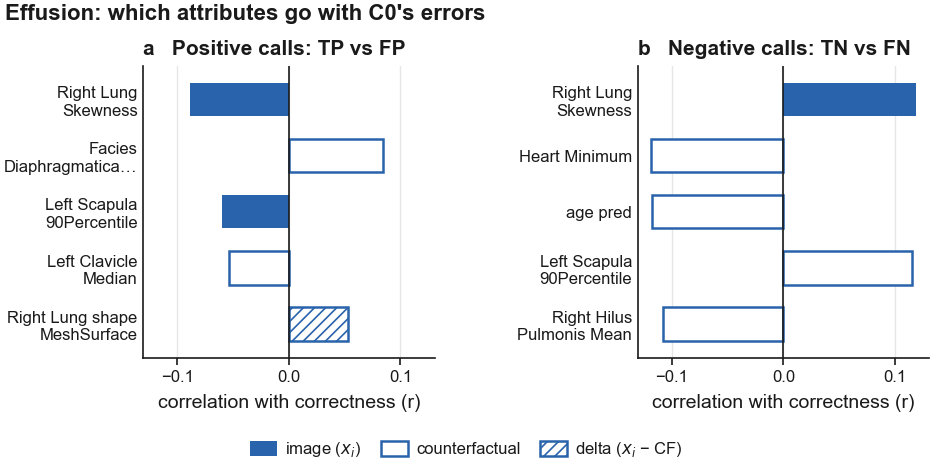

In [7]:
N_KEEP         = 5
MAX_REDUNDANCY = 0.6

def select(ranking, rows):
    """Top N_KEEP attributes of `ranking` whose pairwise |r| on `rows` stays below MAX_REDUNDANCY."""
    d, kept = data[rows], []
    for a in ranking["attribute"]:
        if all(abs(d[a].corr(d[s])) < MAX_REDUNDANCY for s in kept):
            kept.append(a)
        if len(kept) == N_KEEP:
            break
    return kept

def short(f):
    """Readable label: 'Heart_original_firstorder_Mean' -> 'Heart Mean'."""
    s = f.replace("delta_", "Δ ").replace("_original_", " ").replace("firstorder_", "")
    return s.replace("shape2D_", "shape ").replace("_", " ")

selected = {p: select(corr[p], pred == p) for p in SIDES}

# One bar per attribute: its strongest form's r. One hue (attributes blue); the form is the fill,
# as in the dumbbells: solid = image, hollow = counterfactual, hatched = delta.
import textwrap

BLUE        = FAMILY["attr"]
FORM_STYLE  = {"image": dict(color=BLUE),
               "CF":    dict(facecolor="white", edgecolor=BLUE, lw=0.9),
               "delta": dict(facecolor="white", edgecolor=BLUE, lw=0.9, hatch="//////")}
FORM_LABELS = {"image": r"image ($x_i$)", "CF": "counterfactual", "delta": r"delta ($x_i$ − CF)"}
SIDE_TITLE  = {1: "Positive predictions: TP vs FP", 0: "Negative predictions: TN vs FN"}
SIDE_SQ     = 36 * MM                                        # square panel
plt.rcParams["hatch.linewidth"] = 0.6

def wrap(s, width=18):
    """Long labels on two lines, so they do not squeeze the square panels."""
    return "\n".join(textwrap.wrap(s, width, max_lines=2, placeholder="…"))

fig, axes = plt.subplots(1, 2, figsize=(2 * SIDE_SQ + 56 * MM, SIDE_SQ + 24 * MM), sharex=True,
                         layout="constrained")
fig.get_layout_engine().set(w_pad=1 * MM, h_pad=1 * MM, wspace=0.02)
for ax, letter, p in zip(axes, "ab", SIDES):
    top = corr[p].set_index("attribute").loc[selected[p][::-1]]      # best-ranked on top
    y   = np.arange(len(top))
    for yi, (r, form) in zip(y, top[["r_best", "best form"]].itertuples(index=False)):
        ax.barh(yi, r, height=0.6, **FORM_STYLE[form])
    ax.set_yticks(y, [wrap(short(a)) for a in top.index])
    ax.tick_params(axis="y", length=0)
    ax.set_ylim(-0.6, len(top) - 0.4)
    ax.axvline(0, color=INK, lw=LW["axis"])
    ax.grid(axis="x"); ax.set_axisbelow(True)
    ax.set_title(f"{letter}   {SIDE_TITLE[p]}", loc="left")
    ax.set_xlabel("correlation with correctness (r)")
    ax.set_box_aspect(1)                                     # square panels, as everywhere
fig.suptitle(f"{DISEASE.capitalize()}: which attributes go with C0's errors", x=0.01, ha="left")
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, **FORM_STYLE[f]) for f in FORM_STYLE],
           labels=list(FORM_LABELS.values()), loc="outside lower center", ncol=3,
           handlelength=1.6, handleheight=1.0, columnspacing=1.2)
save(fig, "attribute_correlations")
plt.show()


In [8]:
# Print the correlations between the top attributes and the target for each form
for p, title in SIDES.items():
    print(f"{title}:")
    top = corr[p].set_index("attribute").loc[selected[p]]
    display(top[[f"r_{f}" for f in FORMS]].round(3))

# Save the full ranking (every attribute, both sides) for TABLES.ipynb, as
# FIG_DIR/<disease>_<source>_attribute_correlations.csv. Per side and attribute:
#   rank        position in the ranking by |r_best|; selected = 1..N_KEEP in step-4 order, else empty
#   r_<form>    r with correctness, as above
#   d_<form>    mean(correct) - mean(wrong) in SD units of the side (same sign as r)
#   r_msp       r of the best form with threshold MSP: does the attribute just track C0's confidence?
#   r_given_msp partial r of the best form with correctness, MSP held fixed
from c2_msp import msp_score
c0_t = float(open(os.path.join(RESULTS, "C0_final", "multilabel_ignore", DISEASE, "threshold.txt")).read())

def partial_r(r_xy, r_xz, r_yz):
    return (r_xy - r_xz * r_yz) / np.sqrt((1 - r_xz ** 2) * (1 - r_yz ** 2))

saved = []
for p in SIDES:
    d    = data[pred == p]
    ok   = d["correct"].astype(bool)
    msp_p = pd.Series(msp_score(d[f"{DISEASE}_prob"].values, c0_t, "threshold"), index=d.index)
    t = corr[p].copy()
    t.insert(0, "side", p)
    t.insert(1, "rank", np.arange(1, len(t) + 1))
    t.insert(2, "selected", t["attribute"].map({a: i + 1 for i, a in enumerate(selected[p])}).astype("Int64"))
    for form, prefix in FORMS.items():
        X = d[[prefix + a for a in t["attribute"]]]
        t[f"d_{form}"] = ((X[ok].mean() - X[~ok].mean()) / X.std().replace(0, np.nan)).fillna(0).values
    best_cols = [FORMS[f] + a for f, a in zip(t["best form"], t["attribute"])]
    t["r_msp"]       = d[best_cols].corrwith(msp_p).fillna(0).values
    r_ok_msp         = np.corrcoef(d["correct"], msp_p)[0, 1]
    t["r_given_msp"] = partial_r(t["r_best"], t["r_msp"], r_ok_msp)
    t["n_calls"], t["error_rate"], t["r_msp_correct"] = len(d), 1 - ok.mean(), r_ok_msp
    saved.append(t)

saved = pd.concat(saved, ignore_index=True).assign(disease=DISEASE, source=SOURCE)
os.makedirs(FIG_DIR, exist_ok=True)
saved.to_csv(fig_path("attribute_correlations", "csv"), index=False)
print(f"wrote {fig_path('attribute_correlations', 'csv')} ({len(saved):,} rows)")
display(saved[saved["selected"].notna()].sort_values(["side", "selected"], ascending=[False, True])
        [["side", "selected", "rank", "attribute", "best form", "r_best", "r_msp", "r_given_msp"]].round(3))

C0 says positive (TP vs FP):


,r_image,r_CF,r_delta
attribute,,,
Right Lung_original_firstorder_Skewness,-0.089,-0.066,-0.037
Facies Diaphragmatica_bbox_height,0.073,0.084,-0.016
Left Scapula_original_firstorder_90Percentile,-0.060,-0.055,-0.014
Left Clavicle_original_firstorder_Median,-0.037,-0.054,0.015
Right Lung_original_shape2D_MeshSurface,0.003,-0.027,0.053


C0 says negative (TN vs FN):


,r_image,r_CF,r_delta
attribute,,,
Right Lung_original_firstorder_Skewness,0.119,0.115,-0.002
Heart_original_firstorder_Minimum,-0.117,-0.119,0.020
age_pred,-0.067,-0.118,0.043
Left Scapula_original_firstorder_90Percentile,0.108,0.115,-0.028
Right Hilus Pulmonis_original_firstorder_Mean,-0.105,-0.108,0.005


wrote figures/xai/effusion/effusion_diffusion_hml_sub20k_attribute_correlations.csv (922 rows)


,side,selected,rank,attribute,best form,r_best,r_msp,r_given_msp
0,1,1,1,Right Lung_original_firstorder_Skewness,image,-0.089,-0.174,-0.025
1,1,2,2,Facies Diaphragmatica_bbox_height,CF,0.084,0.099,0.051
10,1,3,11,Left Scapula_original_firstorder_90Percentile,image,-0.060,-0.086,-0.030
14,1,4,15,Left Clavicle_original_firstorder_Median,CF,-0.054,-0.044,-0.040
15,1,5,16,Right Lung_original_shape2D_MeshSurface,delta,0.053,0.061,0.033
461,0,1,1,Right Lung_original_firstorder_Skewness,image,0.119,0.275,0.034
462,0,2,2,Heart_original_firstorder_Minimum,CF,-0.119,-0.412,0.016
463,0,3,3,age_pred,CF,-0.118,-0.297,-0.025
464,0,4,4,Left Scapula_original_firstorder_90Percentile,CF,0.115,0.231,0.045
466,0,5,6,Right Hilus Pulmonis_original_firstorder_Mean,CF,-0.108,-0.285,-0.018


## 5. Quadrant profiles: image vs counterfactual

One row per side, one panel per outcome: **TP | FP** on the positive side's attributes, and
**TN | FN** on the negative side's. Each attribute is a dumbbell:

* **filled dot**: the image's average value in that quadrant
* **hollow dot**: the average value of those images' counterfactuals
* **the line between them**: the average difference, i.e. what separates the image from its
  nearest image of the other class. A short line means the two agree on that attribute.

Colour is the organ. Read across a row: where do the correct and the wrong calls differ, and do
they differ in the image, in the counterfactual, or in the gap between them?

**Units: SD.** Raw units differ per attribute (pixel areas, intensities, ratios), so both the
image and the counterfactual values are z-scored with the **same** mean and SD (those of the
images), which puts both dots on one axis and makes the line length the difference in SD units.
0 = the average image.

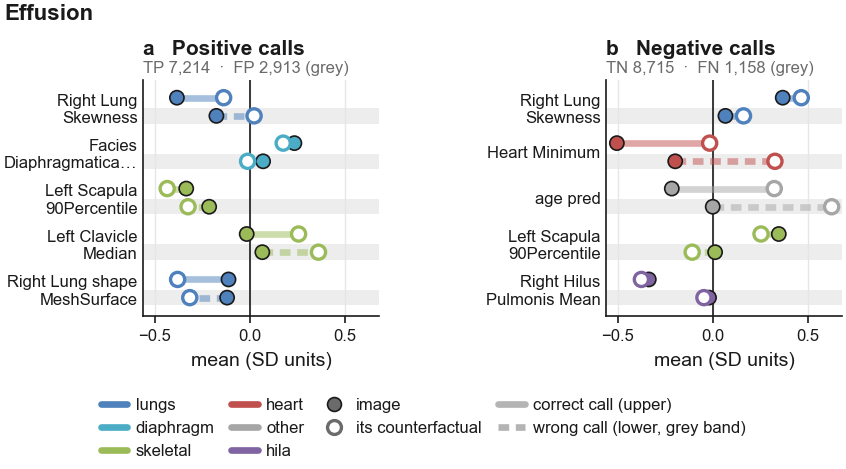

In [9]:
true = data[f"{DISEASE}_true"].astype(int)
quadrant = np.select([(pred == 1) & (true == 1), (pred == 1) & (true == 0),
                      (pred == 0) & (true == 0)], ["TP", "FP", "TN"], "FN")
n_per_q = pd.Series(quadrant).value_counts()
ROWS = {1: ["TP", "FP"], 0: ["TN", "FN"]}     # side -> (correct, wrong) quadrant

# SD units: image and CF values z-scored with the image mean/SD, so both share one axis.
used = list(dict.fromkeys(selected[1] + selected[0]))
mu, sd = data[used].mean(), data[used].std()
zq = (data[used] - mu) / sd                                                        # image
zc = (data[[f"cf_attr_{a}" for a in used]].set_axis(used, axis=1) - mu) / sd       # its CF

# One colour per anatomical group; first match wins, anything else (global ratios, demographics) is grey.
ORGAN_GROUPS = {
    "heart":       (["Heart"],                            "#C0504D"),
    "lungs":       (["Left Lung", "Right Lung"],          "#4F81BD"),
    "hila":        (["Hilus"],                            "#8064A2"),
    "mediastinum": (["Mediastinum", "Aorta", "Weasand"],  "#F79646"),
    "skeletal":    (["Scapula", "Clavicle", "Spine"],     "#9BBB59"),
    "diaphragm":   (["Facies Diaphragmatica"],            "#4BACC6"),
}
def organ_group(f):
    return next((g for g, (keys, _) in ORGAN_GROUPS.items() if any(k in f for k in keys)), "other")
def organ_color(f):
    g = organ_group(f)
    return ORGAN_GROUPS[g][1] if g != "other" else "#A6A6A6"

# Dumbbell sizes at print scale: marker area in pt^2, line widths in pt.
DB = {"line": 2.4, "dot": 26, "edge": 0.6, "hollow": 1.2}

def dumbbell(ax, attrs, img, cf, alpha=1.0, scale=1.0):
    """One row per attribute: filled dot = image, hollow dot = counterfactual, line = the difference."""
    y = np.arange(len(attrs))
    colors = [organ_color(a) for a in attrs]
    for yi, a, c in zip(y, attrs, colors):
        ax.plot([img[a], cf[a]], [yi, yi], color=c, lw=DB["line"] * scale, alpha=0.5 * alpha,
                solid_capstyle="butt", zorder=2)
    ax.scatter(img[attrs], y, s=DB["dot"] * scale, color=colors, edgecolor=INK,
               lw=DB["edge"], alpha=alpha, zorder=3)
    ax.scatter(cf[attrs], y, s=DB["dot"] * scale, facecolor="white", edgecolor=colors,
               lw=DB["hollow"] * scale, alpha=alpha, zorder=3)
    ax.set_yticks(y, [wrap(short(a)) for a in attrs])
    ax.tick_params(axis="y", length=0)
    ax.axvline(0, color=INK, lw=LW["axis"], zorder=1)
    ax.grid(axis="x"); ax.set_axisbelow(True)
    ax.set_ylim(-0.6, len(attrs) - 0.4)                   # half a row of air, no more
    ax.set_box_aspect(1)                                  # square panels, everywhere

groups = list(dict.fromkeys(organ_group(a) for a in used))
organ_handles = [plt.Line2D([], [], color=ORGAN_GROUPS[g][1] if g != "other" else "#A6A6A6",
                            lw=DB["line"]) for g in groups]
style_handles = [plt.Line2D([], [], marker="o", ls="", ms=5, color=MUTED, markeredgecolor=INK,
                            markeredgewidth=DB["edge"]),
                 plt.Line2D([], [], marker="o", ls="", ms=5, markerfacecolor="white",
                            markeredgecolor=MUTED, markeredgewidth=DB["hollow"])]
STYLE_LABELS = ["image", "its counterfactual"]

def add_legends(fig, attrs=None):
    """One legend row under the figure: the organ colours (of `attrs`, default the selected
    attributes), then the two dot styles."""
    gs = groups if attrs is None else list(dict.fromkeys(organ_group(a) for a in attrs))
    handles = [plt.Line2D([], [], color=ORGAN_GROUPS[g][1] if g != "other" else "#A6A6A6",
                          lw=DB["line"]) for g in gs]
    fig.legend(handles=handles + style_handles, labels=gs + STYLE_LABELS,
               loc="outside lower center", ncol=len(gs) + 2)

SQUARE = 34 * MM                                          # side of one square dumbbell panel

def panel_height(n_rows):
    """Figure height (inches) for n_rows stacked square dumbbell panels: titles, x label, legend."""
    return n_rows * (SQUARE + 7 * MM) + 14 * MM

def tighten(fig):
    """Less padding between constrained-layout panels than the matplotlib default."""
    fig.get_layout_engine().set(w_pad=1 * MM, h_pad=1 * MM, wspace=0.02, hspace=0.04)

# ── Correct vs wrong calls in one panel per side ──
WRONG_BG = "#EDEDED"                                      # light grey behind the wrong-call rows
WRONG_LS = (0, (1.6, 1.0))                                # dashes, in units of the line width
OFF      = 0.2                                            # half the gap between the two sub-rows

def dumbbell_pair(ax, attrs, right, wrong):
    """Per attribute two dumbbells: the correct calls on top in full colour, the wrong calls below,
    greyed, dashed and on a grey band. right / wrong: (image means, CF means)."""
    y = np.arange(len(attrs))
    for yi in y:
        ax.axhspan(yi - OFF - 0.17, yi - OFF + 0.17, color=WRONG_BG, lw=0, zorder=0)
    colors = [organ_color(a) for a in attrs]
    for (img, cf), dy, ls in [(right, OFF, "-"), (wrong, -OFF, WRONG_LS)]:
        for yi, a, c in zip(y + dy, attrs, colors):
            ax.plot([img[a], cf[a]], [yi, yi], color=c, lw=DB["line"], alpha=0.5, ls=ls,
                    solid_capstyle="butt", dash_capstyle="butt", zorder=2)
        ax.scatter(img[attrs], y + dy, s=DB["dot"], color=colors, edgecolor=INK, lw=DB["edge"], zorder=3)
        ax.scatter(cf[attrs], y + dy, s=DB["dot"], facecolor="white", edgecolor=colors,
                   lw=DB["hollow"], zorder=3)
    ax.set_yticks(y, [wrap(short(a)) for a in attrs])
    ax.tick_params(axis="y", length=0)
    ax.axvline(0, color=INK, lw=LW["axis"], zorder=1)
    ax.grid(axis="x"); ax.set_axisbelow(True)
    ax.set_ylim(-0.6, len(attrs) - 0.4)
    ax.set_box_aspect(1)                                  # square panels, everywhere

q_img, q_cf = zq.groupby(quadrant).mean(), zc.groupby(quadrant).mean()

SIDE_NAME = {1: "Positive predictions", 0: "Negative predictions"}
fig, axes = plt.subplots(1, 2, figsize=(2 * SQUARE + 52 * MM, SQUARE + 26 * MM), sharex=True,
                         layout="constrained")
tighten(fig)
for ax, letter, (p, (q_ok, q_bad)) in zip(axes, "ab", ROWS.items()):
    attrs = selected[p][::-1]                               # best-ranked attribute on top
    dumbbell_pair(ax, attrs, (q_img.loc[q_ok], q_cf.loc[q_ok]), (q_img.loc[q_bad], q_cf.loc[q_bad]))
    ax.set_title(f"{letter}   {SIDE_NAME[p]}", loc="left", pad=9)
    ax.text(0, 1.015, f"{q_ok} {n_per_q[q_ok]:,}  ·  {q_bad} {n_per_q[q_bad]:,} (grey)",
            transform=ax.transAxes, fontsize=FS["small"], color=MUTED, va="bottom")
    ax.set_xlabel("mean (SD units)")
fig.suptitle(f"{DISEASE.capitalize()}", x=0.01, ha="left")
fig.legend(handles=organ_handles + style_handles
                   + [plt.Line2D([], [], color=MUTED, lw=DB["line"], alpha=0.5),
                      plt.Line2D([], [], color=MUTED, lw=DB["line"], alpha=0.5, ls=WRONG_LS)],
           labels=groups + STYLE_LABELS + ["correct prediction (upper)", "wrong prediction (lower, grey band)"],
           loc="outside lower center", ncol=4, columnspacing=1.0)
save(fig, "quadrant_profiles")
plt.show()


## 6. Groups in a C2 embedding, described by attribute profiles

A C2 MLP, trained to predict whether C0's call is correct, already maps every image into a space
organised by correctness: its last hidden layer (16 units, what the output layer reads). Per side
of C0's call, the images are clustered there with k-means, and each group is described
**afterwards** by its **profile**: the group's mean minus the side's mean, per attribute, as image,
counterfactual and delta (SD units). *What do the images in this group look like?* The side's top
`N_PROFILE` (3) non-redundant attributes of step 4 are drawn as dumbbells, as in step 5 (the CSV
for TABLES keeps all five).

The embeddings come from `code/c2_embed_attributes.py`: the C2 I+C+D model (it reproduces the
published fold-4 scores exactly, and also sees C0's image embeddings, so its groups can rest on
things no attribute measures), fit on folds 0-3 and run on fold 4 only, because the five CV models
do not share an embedding space. So only fold 4's ~18k images are grouped here. Each image's
embedding is the one of its pair with the nearest counterfactual, the same pair the attributes
above describe. The held-out check splits fold 4 by patient: k-means is fit on one half, the other
is only assigned.

Checks per group, in the table:
* **error rate** against the side's base rate: groups that all sit near the base rate are
  image types, not failure modes.
* **error rate (held-out)**: on the half k-means did not see. If a group's error rate holds there,
  it is not a fitting artefact.
* **mean C2 percentile**: does C2's quality score agree with the group's track record? High-error
  groups should sit low (C2 distrusts them) and low-error groups high.
* **mean MSP** (threshold variant, C0's confidence in its own call): if the high-error group is
  also the low-MSP one, it is the same information MSP already has. A high-error group with
  ordinary MSP is the interesting case: confidently wrong, and describable.
* **C2 AUROC / MSP AUROC inside the group**: how well each score still ranks right vs wrong calls
  among the group's images. A group where C2 beats MSP is where C2 adds something MSP does not.

Groups are named **group A, B, C...** by error rate, A the lowest (not C1, C2..., which would
clash with the model names).

First a check: if PC1 of the embedding explains nearly all its variance and tracks the MLP's score,
the embedding is close to one-dimensional, and the groups are little more than bins of the score.


In [10]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from c2_msp import msp_score

EMB_LAYER  = "h16"     # "h16": the last hidden layer | "h32": the one before
EMB_FOLD   = 4         # the fold the MLP was NOT trained on (c2_embed_attributes.py --fold)
N_CLUSTERS = 3

# C0 confidence per image: threshold MSP, from C0's probability and its Youden threshold.
c0_t = float(open(os.path.join(RESULTS, "C0_final", "multilabel_ignore", DISEASE, "threshold.txt")).read())
msp  = msp_score(data[f"{DISEASE}_prob"].values, c0_t, "threshold")

# C2's quality score as a percentile WITHIN C0's call (0 = least trusted, 1 = most trusted):
# the raw score is class-balanced, not calibrated, so only its rank is meaningful.
data["c2_pct"] = data.groupby(pred)["model_score"].rank(pct=True)

def GROUP(k, n=None):
    """Cluster id -> display name: 'group A' is the lowest error rate, then B, C... (n groups,
    default N_CLUSTERS)."""
    return f"group {'ABCDEFGHIJ'[(n or N_CLUSTERS) - k]}"

def summarise_groups(title, rows, labels, held_out, n):
    """Renumber k-means labels 1..n by error rate on the fitting rows (1 = most errors), show the
    group table and return the group id per row."""
    d = pd.DataFrame({"cluster": labels, "error": 1 - data.loc[rows, "correct"].values,
                      "msp": msp[rows], "c2": data.loc[rows, "c2_pct"].values,
                      "score": data.loc[rows, "model_score"].values, "held_out": held_out})
    order = d[~d.held_out].groupby("cluster")["error"].mean().sort_values(ascending=False).index
    d["cluster"] = d["cluster"].map({c: i + 1 for i, c in enumerate(order)})

    def auroc(x, col):                 # how well a score ranks right vs wrong calls within x
        return roc_auc_score(1 - x["error"], x[col]) if x["error"].nunique() == 2 else np.nan

    g = d.groupby("cluster")
    table = pd.DataFrame({
        "n":                        g.size(),
        "error rate":               g["error"].mean(),
        "error rate (held-out)":    d[d.held_out].groupby("cluster")["error"].mean(),
        "mean C2 percentile":       g["c2"].mean(),
        "mean MSP":                 g["msp"].mean(),
        "C2 AUROC":                 pd.Series({k: auroc(x, "score") for k, x in g}),
        "MSP AUROC":                pd.Series({k: auroc(x, "msp") for k, x in g}),
    })
    print(f"{title}: base error rate {d['error'].mean():.3f}, base mean MSP {d['msp'].mean():.3f}, "
          f"AUROC C2 {auroc(d, 'score'):.3f} / MSP {auroc(d, 'msp'):.3f}")
    table.index = table.index.map(lambda k: GROUP(k, n))
    display(table.sort_index().round(3))
    return pd.Series(d["cluster"].values, index=rows)

f = np.load(os.path.join(C2, DISEASE, SOURCE, f"cf_{BEST_K}", "attributes_embeddings",
                         f"fold_{EMB_FOLD}", "full.npz"))
emb_rows = pd.Index(pd.Series(data.index, index=data["path"]).loc[f["paths"]].values)
assert (data.loc[emb_rows, "correct"].values == f["correct"]).all(), "rows do not line up"

H    = f[EMB_LAYER][:, 0]                                 # slot 0: the pair with the nearest CF
live = H.std(axis=0) > 0                                   # dead ReLU units carry nothing
EMB  = pd.DataFrame(H[:, live], index=emb_rows)
emb_prob = pd.Series(f["slot_probs"][:, 0], index=emb_rows)
print(f"C2 MLP, {EMB_LAYER}: {live.sum()}/{len(live)} live units, "
      f"{len(EMB):,} images of fold {EMB_FOLD} | its AUROC "
      f"{roc_auc_score(data.loc[emb_rows, 'correct'], emb_prob):.4f}")

def cluster_space(p, idx):
    """The clustering features of rows `idx`: their embedding (the same space on both sides)."""
    return EMB.loc[idx].values

# Is the embedding close to one-dimensional?
for p, title in SIDES.items():
    rows = emb_rows[(pred.loc[emb_rows] == p).values]
    pca  = PCA().fit(EMB.loc[rows])
    pc1  = pca.transform(EMB.loc[rows])[:, 0]
    print(f"{title}: variance in PC1-3 {np.round(pca.explained_variance_ratio_[:3], 3)} | "
          f"|r(PC1, MLP score)| = {abs(np.corrcoef(pc1, emb_prob.loc[rows])[0, 1]):.3f}")

# Held-out check inside fold 4: k-means fit on one patient-disjoint half, the other only assigned.
fit_half = pd.Series(False, index=emb_rows)
tr, _ = next(GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
             .split(emb_rows, groups=data.loc[emb_rows, "patient_id"]))
fit_half.iloc[tr] = True

cluster = {}                                   # side -> group id per row (1 = most errors)
for p, title in SIDES.items():
    rows   = emb_rows[(pred.loc[emb_rows] == p).values]
    X      = cluster_space(p, rows)
    fit    = fit_half.loc[rows].values
    labels = KMeans(N_CLUSTERS, n_init=10, random_state=42).fit(X[fit]).predict(X)
    cluster[p] = summarise_groups(title, rows, labels, ~fit, N_CLUSTERS)


C2 MLP, h16: 16/16 live units, 4,058 images of fold 4 | its AUROC 0.7787
C0 says positive (TP vs FP): variance in PC1-3 [0.849 0.071 0.023] | |r(PC1, MLP score)| = 0.995
C0 says negative (TN vs FN): variance in PC1-3 [0.902 0.035 0.027] | |r(PC1, MLP score)| = 0.955
C0 says positive (TP vs FP): base error rate 0.298, base mean MSP 0.742, AUROC C2 0.728 / MSP 0.733


,n,error rate,error rate (held-out),mean C2 percentile,mean MSP,C2 AUROC,MSP AUROC
group A,477,0.073,0.071,0.871,0.935,0.615,0.672
group B,718,0.249,0.266,0.554,0.790,0.581,0.592
group C,847,0.466,0.434,0.195,0.593,0.580,0.595


C0 says negative (TN vs FN): base error rate 0.116, base mean MSP 0.885, AUROC C2 0.759 / MSP 0.763


,n,error rate,error rate (held-out),mean C2 percentile,mean MSP,C2 AUROC,MSP AUROC
group A,404,0.015,0.005,0.857,0.987,0.622,0.506
group B,763,0.063,0.070,0.590,0.936,0.670,0.636
group C,849,0.211,0.192,0.227,0.790,0.606,0.639


In [11]:
# Attribute vectors per embedding group. Every attribute z-scored as in step 5 (image mean/SD).
mu_all, sd_all = data[ATTR_COLS].mean(), data[ATTR_COLS].std().replace(0, 1)
ZQ = (data.loc[emb_rows, ATTR_COLS] - mu_all) / sd_all
ZC = (data.loc[emb_rows, CF_COLS].set_axis(ATTR_COLS, axis=1) - mu_all) / sd_all
mask = lambda idx: data.index.isin(idx)                     # row index -> boolean mask over data

def profile(p, in_k):
    """Profile vector: group mean minus side mean per attribute, as image, CF and delta (SD units),
    ranked by its strongest form."""
    rows = cluster[p].index
    img  = ZQ.loc[in_k].mean() - ZQ.loc[rows].mean()
    cf   = ZC.loc[in_k].mean() - ZC.loc[rows].mean()
    out  = pd.DataFrame({"attribute": ATTR_COLS, "image": img.values, "CF": cf.values,
                         "delta": (img - cf).values})
    v    = out[list(FORMS)].to_numpy()
    best = np.abs(v).argmax(axis=1)
    out["best form"] = np.array(list(FORMS))[best]
    out["best"]      = v[np.arange(len(out)), best]
    return out.sort_values("best", key=abs, ascending=False, ignore_index=True)

PROFILE, PROFILE_ATTRS = {}, {}
for p, title in SIDES.items():
    rows = cluster[p].index
    for k in range(N_CLUSTERS, 0, -1):                   # group A first
        in_k = rows[(cluster[p] == k).values]
        PROFILE[p, k] = profile(p, in_k)
        PROFILE_ATTRS.setdefault(p, {})[k] = select(PROFILE[p, k], mask(in_k))

        err = 1 - data.loc[in_k, "correct"].mean()
        print(f"\n{title}, {GROUP(k)} (n = {len(in_k):,}, error {err:.1%}): profile (SD units)")
        display(PROFILE[p, k].set_index("attribute").loc[PROFILE_ATTRS[p][k], list(FORMS)].round(3))

# The step-5 z-frames gain the attributes the embedding groups are described by, so the dumbbells,
# t-SNE map and case cards can draw them.
extra = [a for a in dict.fromkeys(a for p in PROFILE_ATTRS for k in PROFILE_ATTRS[p]
                                  for a in PROFILE_ATTRS[p][k]) if a not in zq.columns]
zq = pd.concat([zq, (data[extra] - mu_all[extra]) / sd_all[extra]], axis=1)
zc = pd.concat([zc, (data[[f"cf_attr_{a}" for a in extra]].set_axis(extra, axis=1)
                     - mu_all[extra]) / sd_all[extra]], axis=1)

held_out = (~fit_half).reindex(data.index, fill_value=False)     # the half k-means did not see

def group_attrs(p, k):
    """The attributes drawn for group k on side p: the group's profile attributes."""
    return PROFILE_ATTRS[p][k]



C0 says positive (TP vs FP), group A (n = 477, error 7.3%): profile (SD units)


,image,CF,delta
attribute,,,
lung_height_ratio,-0.016,-0.672,0.656
Right Lung_original_firstorder_Skewness,-0.384,-0.326,-0.058
Spine_original_firstorder_RootMeanSquared,-0.210,-0.307,0.097
Facies Diaphragmatica_bbox_height,0.273,0.306,-0.033
Left Lung_original_shape2D_Elongation,0.267,0.254,0.013



C0 says positive (TP vs FP), group B (n = 718, error 24.9%): profile (SD units)


,image,CF,delta
attribute,,,
lung_height_ratio,-0.075,-0.611,0.536
Left Scapula_original_firstorder_Minimum,-0.034,-0.114,0.080
Facies Diaphragmatica_original_firstorder_TotalEnergy,0.110,0.107,0.003
Right Scapula_original_shape2D_PerimeterSurfaceRatio,-0.043,-0.107,0.064
Facies Diaphragmatica_perimeter,0.105,0.067,0.038



C0 says positive (TP vs FP), group C (n = 847, error 46.6%): profile (SD units)


,image,CF,delta
attribute,,,
lung_height_ratio,0.073,0.896,-0.824
Facies Diaphragmatica_bbox_height,-0.216,-0.248,0.032
Right Lung_original_firstorder_Skewness,0.243,0.191,0.052
Spine_original_firstorder_RootMeanSquared,0.192,0.214,-0.022
Left Lung_original_shape2D_Elongation,-0.194,-0.200,0.006


... (2 outputs left out)


C0 says negative (TN vs FN), group B (n = 763, error 6.3%): profile (SD units)


,image,CF,delta
attribute,,,
Facies Diaphragmatica_bbox_ratio,0.176,0.146,0.030
Facies Diaphragmatica_original_firstorder_InterquartileRange,-0.144,-0.111,-0.033
Heart_original_shape2D_MinorAxisLength,0.111,0.141,-0.030
Left Lung_original_firstorder_TotalEnergy,0.141,0.113,0.028
Left Hilus Pulmonis_original_firstorder_Variance,0.133,0.022,0.111



C0 says negative (TN vs FN), group C (n = 849, error 21.1%): profile (SD units)


,image,CF,delta
attribute,,,
Heart_original_firstorder_Variance,-0.347,-0.313,-0.033
Right Hilus Pulmonis_original_firstorder_10Percentile,0.253,0.316,-0.063
Aorta_original_firstorder_RobustMeanAbsoluteDeviation,-0.241,-0.273,0.032
Spine_bbox_height,-0.170,-0.272,0.102
Left Hilus Pulmonis_original_firstorder_10Percentile,0.271,0.218,0.053


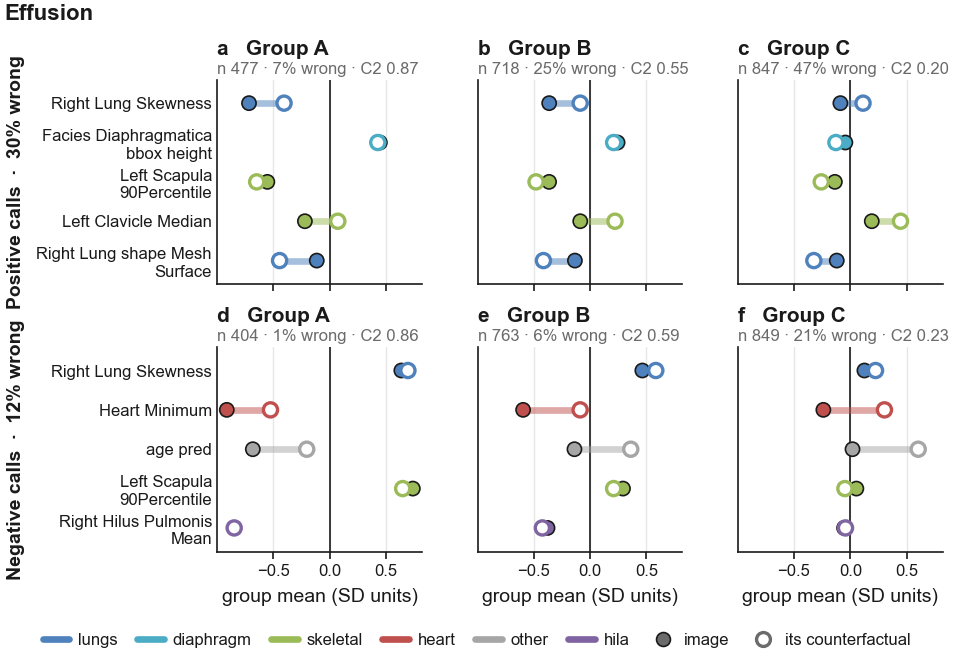

In [13]:
# Embedding groups: one row per side of C0's call, one column per group (A = lowest error rate).
# Every panel shows the side's top N_PROFILE selected attributes (step 4), image vs counterfactual
# (SD units), so the groups of one side can be compared row by row. Three, as the combined card's
# pair card: fewer rows read faster in print, and the CSV below still keeps all N_KEEP.
import re, textwrap

def full_label(a, width=22):
    """The full attribute name, camelCase split into words so it can wrap: never abbreviated."""
    s = re.sub(r"(?<=[a-z])(?=[A-Z])", " ", short(a))
    return "\n".join(textwrap.wrap(s, width))

GROUP_SQ   = 26 * MM                                      # smaller squares: one dumbbell per row
N_PROFILE  = 3                                            # attributes drawn per side: step 4's top
SIDE_COLOR = {1: RAMP["traj"][1], 0: RAMP["cnn"][1]}      # side labels: positive green, negative red
n          = N_CLUSTERS

# The drawn values, saved for TABLES.ipynb (Section 11) as
# FIG_DIR/<disease>_<source>_embedding_group_profiles.csv. One row per side, group and attribute
# (step-4 order, `order` 1 = best-ranked; all N_KEEP, the figure draws the first N_PROFILE): the
# group's image and CF means in SD units, and the group's size, error rate and mean C2 percentile.
# The figure is drawn from this table alone, so it can be redrawn from the CSV without the data.
group_table = []
for p in SIDES:
    rows = cluster[p].index
    for k in range(n, 0, -1):
        in_k = rows[(cluster[p] == k).values]
        group_table.append(pd.DataFrame({
            "side": p, "group": GROUP(k, n)[-1], "order": np.arange(1, len(selected[p]) + 1),
            "attribute": selected[p],
            "image": zq.loc[in_k, selected[p]].mean().values,
            "CF":    zc.loc[in_k, selected[p]].mean().values,
            "n": len(in_k), "error_rate": 1 - data.loc[in_k, "correct"].mean(),
            "n_heldout": int(held_out.loc[in_k].sum()),
            "error_rate_heldout": 1 - data.loc[in_k[held_out.loc[in_k].values], "correct"].mean(),
            "c2_pct": data.loc[in_k, "c2_pct"].mean(),
            "side_n": len(rows), "side_error_rate": 1 - data.loc[rows, "correct"].mean()}))
group_table = pd.concat(group_table, ignore_index=True).assign(disease=DISEASE, source=SOURCE)
os.makedirs(FIG_DIR, exist_ok=True)
group_table.to_csv(fig_path("embedding_group_profiles", "csv"), index=False)
print(f"wrote {fig_path('embedding_group_profiles', 'csv')} ({len(group_table)} rows)")

# The group's colour chip in each panel title, as on the case cards: C0's error rate in the group on
# the side's red-yellow-green scale, centred on the side's error rate (SPAN / ERR_CMAP of step 6b's maps).
from matplotlib.colors import TwoSlopeNorm
from matplotlib.offsetbox import AnnotationBbox, DrawingArea
CHIP_SPAN = {1: 0.30, 0: 0.15}                            # = SPAN: colour range either side of the side's rate
CHIP_PT   = 6                                             # chip side, points (2.2 mm, as on the cards)

def chip_colour(p, e, base):
    """Colour of group error rate e on side p's scale (green = safer, yellow = average, red = riskier)."""
    norm = TwoSlopeNorm(vcenter=base, vmin=max(0, base - CHIP_SPAN[p]), vmax=min(1, base + CHIP_SPAN[p]))
    return plt.get_cmap("RdYlGn_r")(norm(e))

def group_title(ax, letter, g, colour):
    """Panel title 'letter  [chip] Group g': the chip and the name are placed after the letter."""
    t  = ax.set_title(letter, loc="left", pad=9)          # the left title (ax.title is the centre one)
    da = DrawingArea(CHIP_PT, CHIP_PT)
    da.add_artist(plt.Rectangle((0, 0), CHIP_PT, CHIP_PT, facecolor=colour, edgecolor="none"))
    ax.add_artist(AnnotationBbox(da, (1, 0.5), xycoords=t, xybox=(5, 0), boxcoords="offset points",
                                 box_alignment=(0, 0.5), frameon=False, pad=0, annotation_clip=False))
    ax.annotate(f"Group {g}", (1, 0), xycoords=t, xytext=(5 + CHIP_PT + 3, 0),
                textcoords="offset points", ha="left", va="bottom",
                fontsize=t.get_fontsize(), fontweight=t.get_fontweight(), color=INK)

def subtitle(ax, parts):
    """Grey line under the panel title from (text, bold) pieces, on one baseline."""
    from matplotlib.offsetbox import HPacker, TextArea
    kw  = dict(fontsize=FS["small"], color=MUTED)
    box = HPacker(children=[TextArea(s, textprops=dict(kw, fontweight="bold" if b else "normal"))
                            for s, b in parts], align="baseline", pad=0, sep=0)
    ax.add_artist(AnnotationBbox(box, (0, 1.015), xycoords="axes fraction", box_alignment=(0, 0),
                                 frameon=False, pad=0, annotation_clip=False))

def plot_group_profiles(table):
    """The group-profile figure from `table` (the CSV above): one row per side, one column per group."""
    sides   = [p for p in SIDE_NAME if p in set(table["side"])]          # positive predictions on top
    groups_ = sorted(table["group"].unique())                            # A = lowest error rate
    fig, axes = plt.subplots(len(sides), len(groups_),
                             figsize=(len(groups_) * GROUP_SQ + 46 * MM,
                                      len(sides) * (GROUP_SQ + 8 * MM) + 16 * MM),
                             sharex=True, sharey="row", layout="constrained", squeeze=False)
    tighten(fig)
    letters = iter("abcdefghij")
    drawn = []
    for row, p in zip(axes, sides):
        t     = table[table["side"] == p]
        attrs = (t[t["group"] == groups_[0]].sort_values("order")["attribute"]
                 .head(N_PROFILE).tolist()[::-1])                         # best-ranked attribute on top
        drawn += attrs[::-1]                              # legend in step-4 order, as before
        for ax, g in zip(row, groups_):
            tg = t[t["group"] == g].set_index("attribute")
            dumbbell(ax, attrs, tg["image"], tg["CF"])
            r = tg.iloc[0]
            group_title(ax, next(letters), g, chip_colour(p, r["error_rate"], r["side_error_rate"]))
            # Error rate and n on the held-out half only (rows k-means did not see), as on the t-SNE
            # map, the case cards and in the text. The chip colour, as on the case cards, is the
            # whole group's rate; the profile values above are whole-group means.
            subtitle(ax, [(f"n {r['n_heldout']:,.0f} · ", False), (f"{r['error_rate_heldout']:.0%} wrong", True),
                          (f" · C2 {r['c2_pct']:.2f}", False)])
        row[0].set_yticklabels([full_label(a) for a in attrs])            # labels once per side
        # Side label: the side in its colour, bold, on two lines ("Positive" / "predictions"), then the
        # side's error rate beside it, in the room the larger labelpad leaves before the ticks.
        row[0].set_ylabel(SIDE_NAME[p].replace(" ", "\n"), color=SIDE_COLOR[p], fontweight="bold",
                          fontsize=FS["head"] + 1, labelpad=FS["base"] + 6)
        row[0].annotate(f"{t['side_error_rate'].iloc[0]:.0%} wrong", xy=(1, 0.5),
                        xycoords=row[0].yaxis.label, xytext=(2, 0), textcoords="offset points",
                        rotation=90, ha="left", va="center", fontsize=FS["base"], color=INK)
        for ax in row[1:]:
            ax.tick_params(axis="y", labelleft=False)
    fig.align_ylabels(axes[:, 0])                         # side labels in one column, whatever the label widths
    for ax in axes[-1]:
        ax.set_xlabel("group mean (SD units)")
    fig.suptitle(f"{table['disease'].iloc[0].capitalize()}", x=0.01, ha="left")
    add_legends(fig, drawn)                               # only the organs drawn
    return fig

fig = plot_group_profiles(group_table)
save(fig, "embedding_group_profiles")
plt.show()

### 6b. Which information separates C0's errors?

The same fold-4 images, grouped and mapped in four spaces, each adding to the one before:

| column | space | what it holds |
|---|---|---|
| **a / e** | attributes (I) | the image's own measurements |
| **b / f** | delta (I − CF) | how the image differs from its counterfactual |
| **c / g** | I + delta | both (the CF itself adds nothing new: CF = I − delta) |
| **d / h** | C2 embedding | the hidden layer of the C2 MLP, as in step 6 |

In every space the images are clustered with k-means (fit on one patient half of fold 4) and drawn
on their own t-SNE map, using the same sampled images in every column. The raw spaces are z-scored
and reduced with PCA to 16 dimensions, the width of the C2 embedding.

* **Colour**: C0's local error rate on the map (share of wrong calls among each point's nearest
  neighbours), centred on the side's overall error rate: yellow = as often wrong as average,
  red = more often, green = less often.
* **Lines and letters**: the k-means groups of that space. Letters are assigned per space by error
  rate (A = lowest), so group A of one column is not the same set of images as group A of another.
  The corner box gives each group's error rate on the held-out half.
* **Error spread**: the gap between the highest and lowest group error rate on the held-out half,
  in percentage points. 0 means the groups are image types that C0 handles equally well; a wide
  spread means the space separates where C0 fails.

If a space separates C0's errors, its map splits into red and green regions and its error spread
widens. Column **d** is not a like-for-like step: the C2 embedding was *trained* to predict
correctness and also sees C0's image embedding. The kNN AUROC per space, against MSP, is in the
summary table printed by the next cell.


In [ ]:
# The C2 map and its colour scale, shared by the four-spaces figure and the case cards. Enough on
# its own for the case cards: the four-spaces comparison (next two cells) runs only if STUDY_SPACES.
from sklearn.manifold import TSNE
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from scipy.ndimage import gaussian_filter, distance_transform_edt
from matplotlib.collections import Collection
import matplotlib.patheffects as pe

STUDY_SPACES = False                             # run the four-spaces comparison (next two cells)

TSNE_N    = 5000                                 # images per side on the maps (t-SNE is slow)
DOT_SIZE  = 3                                    # scatter marker area (pt²)
LOCAL_K   = max(10, TSNE_N // 100)              # neighbours for the local error rate
SPAN      = {1: 0.30, 0: 0.15}                   # colour range either side of the side's error rate
HALO      = [pe.withStroke(linewidth=1.8, foreground="white")]
ERR_CMAP  = "RdYlGn_r"                           # green = less often wrong, yellow = average, red = more

from tsne_cache import cached_tsne
TSNE_CACHE = os.path.join(C2, DISEASE, SOURCE, "tsne_cache")   # maps reused across runs (code/tsne_cache.py)

def tsne_sample(rows):
    """The images of `rows` drawn on the maps: the same sample in every space."""
    return rows[np.random.default_rng(42).choice(len(rows), min(TSNE_N, len(rows)), replace=False)]

TSNE_MAP = {}                                    # side -> (sampled rows, C2 map)
for p in SIDES:
    idx = tsne_sample(emb_rows[(pred.loc[emb_rows] == p).values])
    TSNE_MAP[p] = (idx, cached_tsne(cluster_space(p, idx), TSNE_CACHE,
                                    f"attr_{BEST_CONFIG}_K{BEST_K}_side{p}"))

def tsne_position(p, row, n_nn=10):
    """Where `row` sits on side p's C2 map. t-SNE cannot place a new point, so a row outside the
    sample is put at the mean position of its n_nn nearest sampled neighbours in the C2 space."""
    idx, emb = TSNE_MAP[p]
    j = idx.get_indexer([row])[0]
    if j >= 0:
        return emb[j]
    d = np.linalg.norm(cluster_space(p, idx) - cluster_space(p, [row])[0], axis=1)
    return emb[np.argsort(d)[:n_nn]].mean(axis=0)

def map_limits(emb, q=0.5, pad=0.06):
    """Axis limits from the 0.5-99.5 percentile of the map, so stray points do not shrink it."""
    lo, hi = np.percentile(emb, [q, 100 - q], axis=0)
    return lo - pad * (hi - lo), hi + pad * (hi - lo)

def territories(ax, emb, labels, lims, n_grid=250, k=50, sigma=3):
    """Smoothed borders between the groups' regions on the map, and each group's letter at the most
    interior point of its region (farthest from any border or blank area). Each group's share among
    a grid cell's k nearest points is smoothed; a border runs where two groups' shares are equal.
    Cells far from any point stay blank."""
    lo, hi = emb.min(axis=0), emb.max(axis=0)
    gx, gy = np.meshgrid(*[np.linspace(l, h, n_grid) for l, h in zip(lo, hi)])
    G      = np.c_[gx.ravel(), gy.ravel()]
    ids    = np.unique(labels)
    P      = KNeighborsClassifier(k).fit(emb, labels).predict_proba(G).reshape(*gx.shape, len(ids))
    P      = np.stack([gaussian_filter(P[..., i], sigma) for i in range(len(ids))], axis=-1)
    d, _   = NearestNeighbors(n_neighbors=1).fit(emb).kneighbors(G)
    far    = gaussian_filter((d.reshape(gx.shape) > 0.03 * (hi - lo).max()).astype(float), 2) > 0.5
    shown  = ((gx > lims[0][0]) & (gx < lims[1][0]) & (gy > lims[0][1]) & (gy < lims[1][1]))
    win    = P.argmax(axis=-1)

    for i, g in enumerate(ids):
        margin = np.ma.masked_where(far, P[..., i] - np.delete(P, i, axis=-1).max(axis=-1))
        cs = ax.contour(gx, gy, margin, levels=[0], colors=INK, linewidths=0.7, zorder=3)
        for c in ([cs] if isinstance(cs, Collection) else cs.collections):
            c.set_path_effects(HALO)

        region = (win == i) & ~far & shown
        if not region.any():
            continue
        depth = distance_transform_edt(np.pad(region, 1))[1:-1, 1:-1]   # distance to the region's edge
        j = np.unravel_index(depth.argmax(), depth.shape)
        t = ax.text(gx[j], gy[j], GROUP(g)[-1], ha="center", va="center", fontsize=FS["base"],
                    fontweight="bold", color=INK, zorder=5, clip_on=True,
                    bbox=dict(boxstyle="circle,pad=0.2", facecolor="white", edgecolor=INK,
                              lw=0.4, alpha=0.9))
        t.set_in_layout(False)                   # never shrinks the panel

In [ ]:
if STUDY_SPACES:
    from sklearn.neighbors import NearestNeighbors
    from sklearn.preprocessing import StandardScaler
    from sklearn.decomposition import PCA
    from sklearn.cluster import KMeans
    from sklearn.metrics import roc_auc_score

    SPACE_DIM = 16                                   # raw spaces are reduced to the C2 embedding's width
    KNN_K     = 50                                   # neighbours for the kNN AUROC, in the space itself

    # name -> (column title, raw features of rows idx)
    SPACES = {
        "I":   ("Attributes (I)",     lambda idx: data.loc[idx, ATTR_COLS].values),
        "D":   ("Delta (I − CF)",     lambda idx: data.loc[idx, DELTA_COLS].values),
        "I+D": ("Attributes + delta", lambda idx: data.loc[idx, ATTR_COLS + DELTA_COLS].values),
        "C2":  ("C2 embedding",       lambda idx: EMB.loc[idx].values),
    }

    def space_features(s, rows, fit):
        """Clustering features of `rows` in space s. Raw spaces: z-scored and PCA'd to SPACE_DIM, both
        fit on the fitting half. C2: the step-6 embedding unchanged, so its groups reproduce step 6."""
        X = SPACES[s][1](rows).astype(float)
        if s == "C2":
            return X
        Z = np.nan_to_num(StandardScaler().fit(X[fit]).transform(X))
        return PCA(SPACE_DIM, random_state=42).fit(Z[fit]).transform(Z)

    SPACE_RES = {}                                   # (side, space) -> map, groups and metrics
    for p, title in SIDES.items():
        rows = emb_rows[(pred.loc[emb_rows] == p).values]
        fit  = fit_half.loc[rows].values
        ok   = data.loc[rows, "correct"].values.astype(int)
        idx  = tsne_sample(rows)
        pos  = rows.get_indexer(idx)

        for s, (name, _) in SPACES.items():
            X      = space_features(s, rows, fit)
            labels = KMeans(N_CLUSTERS, n_init=10, random_state=42).fit(X[fit]).predict(X)
            groups = summarise_groups(f"{title} · {name}", rows, labels, ~fit, N_CLUSTERS)

            # kNN correctness: neighbours from the fitting half, scored on the held-out half
            _, nb   = NearestNeighbors(n_neighbors=KNN_K).fit(X[fit]).kneighbors(X[~fit])
            knn_auc = roc_auc_score(ok[~fit], ok[fit][nb].mean(axis=1))

            emb    = (TSNE_MAP[p][1] if s == "C2" else                 # C2: the map of the cell above
                      cached_tsne(X[pos], TSNE_CACHE, f"attr_{s}_K{BEST_K}_side{p}"))
            err_ho = {k: 1 - ok[~fit][groups.values[~fit] == k].mean() for k in range(N_CLUSTERS, 0, -1)}
            SPACE_RES[p, s] = dict(idx=idx, emb=emb, groups=groups.loc[idx].values,
                                   err_ho=err_ho, knn_auc=knn_auc)
        SPACE_RES[p, "MSP"] = roc_auc_score(ok[~fit], msp[rows][~fit])

    # One table for the text: does each step add structure?
    summary = pd.DataFrame([
        {"side": SIDE_NAME[p], "space": SPACES[s][0],
         "kNN AUROC": SPACE_RES[p, s]["knn_auc"],
         "group error spread (held-out)": max(SPACE_RES[p, s]["err_ho"].values())
                                          - min(SPACE_RES[p, s]["err_ho"].values()),
         "MSP AUROC": SPACE_RES[p, "MSP"]}
        for p in SIDES for s in SPACES])
    display(summary.set_index(["side", "space"]).round(3))
else:
    print("four-spaces comparison skipped (STUDY_SPACES = False)")


In [ ]:
if STUDY_SPACES:
    from sklearn.neighbors import NearestNeighbors
    from matplotlib.colors import TwoSlopeNorm
    from matplotlib.lines import Line2D

    SPACE_SQ  = 38 * MM                              # square map panel
    SEP_GAP   = 0.18                                 # empty column before the C2 map, in panel widths

    def group_rates(ax, err):
        """Each group's held-out error rate, stacked in the panel's lower-right corner."""
        lines = ["wrong"] + [f"{GROUP(k)[-1]}  {e:.0%}" for k, e in err.items()]
        ax.text(0.99, 0.01, "\n".join(lines), transform=ax.transAxes, ha="right", va="bottom",
                fontsize=FS["base"], color=INK, linespacing=1.25, zorder=6,
                bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor=HAIR, lw=0.4,
                          alpha=0.9))

    # Panels on a grid with an empty spacer column before the C2 embedding, for the separator line.
    n_sp = len(SPACES)
    fig  = plt.figure(figsize=(FULL, len(SIDES) * (SPACE_SQ + 16 * MM) + 6 * MM), layout="constrained")
    gs   = fig.add_gridspec(len(SIDES), n_sp + 1, width_ratios=[1] * (n_sp - 1) + [SEP_GAP, 1])
    cols = list(range(n_sp - 1)) + [n_sp]            # skip the spacer column
    axes = np.array([[fig.add_subplot(gs[r, c]) for c in cols] for r in range(len(SIDES))])
    tighten(fig)

    letters = iter("abcdefgh")
    for row, p in zip(axes, SIDES):
        rows = emb_rows[(pred.loc[emb_rows] == p).values]
        base = 1 - data.loc[rows, "correct"].mean()
        norm = TwoSlopeNorm(vcenter=base, vmin=max(0, base - SPAN[p]), vmax=min(1, base + SPAN[p]))

        for ax, (s, (name, _)) in zip(row, SPACES.items()):
            r = SPACE_RES[p, s]
            idx, emb, lab = r["idx"], r["emb"], r["groups"]
            lims = map_limits(emb)

            # C0's local error rate: share of wrong calls among each point's LOCAL_K map neighbours
            _, nb     = NearestNeighbors(n_neighbors=LOCAL_K).fit(emb).kneighbors(emb)
            local_err = 1 - data.loc[idx, "correct"].values[nb].mean(axis=1)
            sc = ax.scatter(*emb.T, c=local_err, cmap=ERR_CMAP, norm=norm, s=DOT_SIZE, lw=0,
                            rasterized=True)
            territories(ax, emb, lab, lims)
            group_rates(ax, r["err_ho"])

            # header: panel name, then the error spread (held-out, highest minus lowest group)
            spread = max(r["err_ho"].values()) - min(r["err_ho"].values())
            ax.set_title(f"{next(letters)}   {name}", loc="left", pad=14)
            ax.text(0, 1.02, f"error spread {spread * 100:.1f} pts", transform=ax.transAxes,
                    fontsize=FS["head"], fontweight="bold", color=MUTED, va="bottom")

            ax.set_xlim(lims[0][0], lims[1][0]); ax.set_ylim(lims[0][1], lims[1][1])
            ax.set_xticks([]); ax.set_yticks([])
            ax.spines[["left", "bottom"]].set_visible(False)
            ax.set_aspect("equal", adjustable="datalim")
            ax.set_box_aspect(1)

        row[0].set_ylabel(f"{SIDE_NAME[p]}\n{base:.0%} wrong", fontweight="bold", labelpad=4)
        cb = fig.colorbar(sc, ax=list(row), shrink=0.8, aspect=18, pad=0.02, label="local C0 error rate")
        cb.set_ticks([norm.vmin, base, norm.vmax],
                     labels=[f"{norm.vmin:.0%}", f"{base:.0%} (all)", f"{norm.vmax:.0%}"])

    fig.align_ylabels(axes[:, 0])
    fig.suptitle(f"{DISEASE.capitalize()}: where C0 is wrong, in four spaces", x=0.01, ha="left")

    # Dashed separator before the C2 embedding: the layout is computed once, then frozen, so the line
    # sits in the middle of the spacer column.
    fig.canvas.draw()
    fig.set_layout_engine("none")
    to_fig = fig.transFigure.inverted()
    rend   = fig.canvas.get_renderer()
    left   = [ax.get_tightbbox(rend).transformed(to_fig) for ax in axes[:, -2]]
    right  = [ax.get_tightbbox(rend).transformed(to_fig) for ax in axes[:, -1]]
    x      = (max(b.x1 for b in left) + min(b.x0 for b in right)) / 2
    y0, y1 = min(b.y0 for b in right), max(b.y1 for b in right)
    fig.add_artist(Line2D([x, x], [y0, y1], transform=fig.transFigure, color=GREY,
                          lw=LW["ref"], ls=(0, (4, 3))))

    save(fig, "tsne_spaces")
    plt.show()
else:
    print("four-spaces figure skipped (STUDY_SPACES = False)")


## 7. Case cards

One image taken through the pipeline, one square panel per step:

| panel | step |
|---|---|
| **a** C0's call | the input X-ray (organs outlined): what C0 predicts, with what probability, and whether it was right |
| **b** Most similar X-ray of the other class | its counterfactual, and C0's probability for it |
| **c** What changes | the **group's profile attributes** (step 6), image (filled) vs counterfactual (hollow): upper = this image, lower on the grey band = its group's average |
| **d** Where C0 is wrong | the C2 map of step 6b: local error rate (green = safer, yellow = average, red = riskier), group borders and letters, this image as a star |
| **e** Similar past cases | the four members closest to its group's centre, tagged with their outcome |
| **f** How often C0 is wrong | errors per 100 in this image's group vs the side's other calls; bar in the map's colour |
| **g** How much to trust this call | trust meter: ▼ C2 rank and △ MSP rank, with the deferral cut at `COVERAGE` |
| **h** Key | every legend of the card |

The caption (title chain, error rates, ranks, deferral verdicts) is written to a `.txt` beside each
saved card. On the map, an image outside the t-SNE sample is placed at the mean position of its 10
nearest sampled neighbours in the C2 space (t-SNE cannot embed a new point).

Needs only the step-6b helpers cell (the C2 map `TSNE_MAP`, its colour scale and the group
borders); the four-spaces comparison and figure run only with `STUDY_SPACES = True`.

**Ranks and coverage.** `SCORE_SCOPE = "all"` ranks every call of a fold together, as E-AURC and the
risk-coverage curves do, so `COVERAGE` (one global cut for every card) is the real deferral cut;
`"side"` ranks within C0's call.

**`pick_case`** chooses the example: a **held-out** image (its group was fit without it), with the
wanted outcome, among the most typical half of its group, with the clearest assignment.
* `c2="agree"` keeps images where C2 clearly points the right way (top third of C2 ranks for a
  correct call, bottom third for a wrong one), `"disagree"` the opposite, `None` ignores it.
* `c2_cut` / `msp_cut` = `"accept"` or `"defer"`: where C2 / MSP put the call at `COVERAGE`, at
  least `margin` away from the cut.
* `nth` picks a runner-up from the printed table; any of its row numbers can also go straight to
  `case_card`.


In [16]:
import textwrap
from sklearn.neighbors import NearestNeighbors
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import TwoSlopeNorm

# The error map in panel d is the C2 map of the four-spaces figure: its sample, colours and groups.
_missing = [n for n in ("TSNE_MAP", "territories", "map_limits", "ERR_CMAP", "SPAN", "LOCAL_K")
            if n not in globals()]
assert not _missing, f"run the step-6b C2-map helpers cell first; missing: {_missing}"

DATA_ROOT      = os.environ.get("THESIS_DATA", "/work3/s251710/thesis_data")
LETTERS        = "ABCDEFGHIJ"
SEG_ON_TYPICAL = True      # also draw the organs on the four typical images of the group
SCORE_SCOPE = "all"    # trust ranks: "all" = every call of the image's fold, as E-AURC ranks them
                       # (one global deferral cut); "side" = only calls with the same C0 call
COVERAGE    = 0.80     # ONE global coverage for every card: C2 keeps this share of all calls in a
                       # fold (positive and negative together), defers the least trusted rest

DISPLAY_SIZE   = 320       # every image is drawn as a DISPLAY_SIZE x DISPLAY_SIZE square (resized, not cropped)
CARD_DOT       = globals().get("DOT_SIZE", 3)   # map dot size, as in the four-spaces figure

# ── Organ segmentation: the PSPNet the C1 attributes were measured with, same preprocessing ──
# Model and mask cache survive re-running this cell (segmenting is the slow part of a card);
# on a GPU node the model runs there.
SEG_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if "SEG_MODEL" not in globals():
    SEG_MODEL = xrv.baseline_models.chestx_det.PSPNet().eval()
SEG_MODEL  = SEG_MODEL.to(SEG_DEVICE)
SEG_RESIZE = xrv.datasets.XRayResizer(224)
_seg_cache = globals().get("_seg_cache", {})

def organ_masks(path):
    """{organ: binary mask at DISPLAY_SIZE x DISPLAY_SIZE}, preprocessed exactly as in C1."""
    if path not in _seg_cache:
        img = np.asarray(Image.open(os.path.join(DATA_ROOT, path)).convert("L"), dtype=np.float32)
        x = SEG_RESIZE(xrv.datasets.normalize(img, 255)[None])        # (1, 224, 224), [-1024, 1024]
        with torch.no_grad(), warnings.catch_warnings():
            warnings.simplefilter("ignore")                            # "224 is not native 512": same as C1
            out = torch.sigmoid(SEG_MODEL(torch.from_numpy(x)[None].to(SEG_DEVICE))).cpu().numpy()[0]
        _seg_cache[path] = {
            name: np.asarray(Image.fromarray((m >= 0.5).astype(np.uint8))
                             .resize((DISPLAY_SIZE, DISPLAY_SIZE), Image.NEAREST))
            for name, m in zip(SEG_MODEL.targets, out)}
    return _seg_cache[path]


# Panel c and the organ outlines use group_attrs (step 6): the GROUP's own profile attributes.

def case_organs(p, k):
    """The segmented organs behind the attributes drawn for group k (global ones like age have none)."""
    return [t for t in SEG_MODEL.targets if any(t in a for a in group_attrs(p, k))]

def overlay_organs(ax, path, organs, alpha=0.22, lw=0.9):
    """Each organ: full outline in its legend colour, soft transparent fill."""
    masks = organ_masks(path)
    for organ in organs:
        m = masks.get(organ)
        if m is None or not m.any():
            continue
        c = organ_color(organ)
        ax.contourf(m, levels=[0.5, 1.5], colors=[to_rgba(c, alpha)])
        ax.contour(m, levels=[0.5], colors=[c], linewidths=lw)

# ── Case selection and drawing ──
def group_geometry(p):
    """Clustering-space coordinates and group centres for side p."""
    rows = cluster[p].index
    X    = pd.DataFrame(cluster_space(p, rows), index=rows)
    return X, X.groupby(cluster[p]).mean()

# Trust ranks (0 = least, 1 = most trusted) of C2 and MSP, for the trust meter and pick_case.
# "all": within each fold over positive AND negative calls -- the ranking E-AURC and the
# risk-coverage curves use, so the COVERAGE cut is the real one. "side": within C0's call,
# pooled over folds.
RANK_KEYS  = {"all": [data["fold"]], "side": [pred]}[SCORE_SCOPE]
SCOPE_TEXT = {"all": "all calls", "side": None}[SCORE_SCOPE]  # None: "{side} calls", per card
data["c2_rank"]  = data["model_score"].groupby(RANK_KEYS).rank(pct=True)
data["msp_rank"] = pd.Series(msp, index=data.index).groupby(RANK_KEYS).rank(pct=True)

def pick_case(p, group, outcome="correct", n_show=5, c2="agree", c2_cut=None, msp_cut=None,
              margin=0.05, nth=0):
    """Row of a typical, clearly assigned held-out image of `group` ('A', 'B'...) on side p.

    c2="agree": C2 clearly points the right way (top third of C2 ranks for a correct call,
    bottom third for a wrong one); "disagree": clearly the wrong way; None: not used.
    All ranks are the SCORE_SCOPE ranks (c2_rank / msp_rank), as drawn on the trust meter.
    c2_cut / msp_cut: "accept" or "defer": where C2 / MSP put the call at COVERAGE, at least
    `margin` away from the cut so the verdict on the trust meter is not a coin flip; None: not used.
    nth: which candidate of the ranked table to return (0 = the clearest).
    """
    assert group in LETTERS[:N_CLUSTERS], f"only groups {LETTERS[:N_CLUSTERS]} exist"
    k      = N_CLUSTERS - LETTERS.index(group)                  # letter -> internal cluster id
    X, centres = group_geometry(p)
    in_k   = cluster[p].index[(cluster[p] == k).values]
    cand   = in_k[held_out.loc[in_k].values]                     # not seen by k-means
    if outcome is not None:
        cand = cand[data.loc[cand, "correct"].values == (outcome == "correct")]
    if c2 is not None:
        pct     = data.loc[cand, "c2_rank"].values
        correct = data.loc[cand, "correct"].values == 1
        right   = np.where(correct, pct >= 2 / 3, pct <= 1 / 3)       # C2 clearly right
        wrong   = np.where(correct, pct <= 1 / 3, pct >= 2 / 3)       # C2 clearly wrong
        cand    = cand[right if c2 == "agree" else wrong]
    thr = 1 - COVERAGE                                           # trust-meter cut (rank)
    for col, cut in [("c2_rank", c2_cut), ("msp_rank", msp_cut)]:
        if cut is not None:
            v    = data.loc[cand, col].values
            cand = cand[v >= thr + margin if cut == "accept" else v < thr - margin]
    assert len(cand), "no candidate matches these filters (try a smaller margin, or c2=None)"

    dist  = pd.DataFrame(np.linalg.norm(X.loc[cand].values[:, None, :] - centres.values[None], axis=2),
                         index=cand, columns=centres.index)
    a     = group_attrs(p, k)
    gap   = ((zq.loc[cand, a] - zq.loc[in_k, a].mean()).abs().mean(axis=1)
             + (zc.loc[cand, a] - zc.loc[in_k, a].mean()).abs().mean(axis=1)) / 2
    score = pd.DataFrame({"clearness": dist.drop(columns=k).min(axis=1) / dist[k],
                          "profile gap": gap, "outcome": quadrant[cand],
                          "C2 rank": data.loc[cand, "c2_rank"],
                          "MSP rank": data.loc[cand, "msp_rank"],
                          "path": data.loc[cand, "path"]})
    score = score[score["profile gap"] <= score["profile gap"].median()]
    score = score.sort_values("clearness", ascending=False)
    print(f"{len(score)} candidates")
    display(score.head(max(n_show, nth + 1)).round(3))
    return score.index[nth]

STAR = "#FFC20A"

# Plain-language outcome of each call, for the panels (the caption keeps TP/FP, C0, C2)
OUTCOME = {"TP": "✓ true positive", "TN": "✓ true negative",
           "FP": "✗ false positive", "FN": "✗ false negative"}
TAG     = {q: v.replace(" ", "\n", 2).replace("\n", " ", 1)     # "✓ true\npositive": fits the
           for q, v in OUTCOME.items()}                            # small images in e
GLYPHS  = ["Arial", "DejaVu Sans"]                # Arial has no ✓ ✗ △: fall back to DejaVu for those

# ── Case-card grid (mm): 4 x 2 equal squares, equal gaps, every title at the same height ──
CARD_W  = FULL / MM                               # 183 mm
CARD_M  = 4                                       # left / right margin
CARD_G  = 9                                       # gap between columns
CARD_S  = (CARD_W - 2 * CARD_M - 3 * CARD_G) / 4  # side of one square panel (37 mm)
CARD_HD = 3                                       # top margin (the caption goes to a .txt beside the figure)
CARD_T  = (11, 14)                                # per row: title lines (2, then 3 for e) + subtitle
CARD_R  = 9                                       # tick labels / x label under the first row
CARD_B  = 4                                       # under the second row
CARD_H  = CARD_HD + sum(CARD_T) + 2 * CARD_S + CARD_R + CARD_B
TITLE_LINE = 3.2                                  # mm per title line (7.5 pt)
TITLE_WRAP = 28                                   # characters per title line (fits square + gap)

def card_cell(r, c):
    """[left, bottom, width, height] (figure fraction) of the square in row r, column c."""
    top = CARD_HD + CARD_T[0] + r * (CARD_S + CARD_R + CARD_T[1])
    x   = CARD_M + c * (CARD_S + CARD_G)
    return [x / CARD_W, 1 - (top + CARD_S) / CARD_H, CARD_S / CARD_W, CARD_S / CARD_H]

def card_title(fig, r, c, letter, head, sub=""):
    """Panel letter + bold title (wrapped onto a second line if needed, or at an explicit '\n'),
    muted subtitle right under it. The first title line sits at the same height in every panel."""
    x, y, _, h = card_cell(r, c)
    y_top = y + h + (CARD_T[r] - 0.5) / CARD_H
    lines = head.split("\n") if "\n" in head else textwrap.wrap(head, TITLE_WRAP)
    kw = dict(fontsize=FS["title"], fontweight="bold", va="top", linespacing=1.15)
    fig.text(x, y_top, letter, **kw)
    fig.text(x + 3.4 / CARD_W, y_top, "\n".join(lines), **kw)
    fig.text(x, y_top - (len(lines) * TITLE_LINE + 0.6) / CARD_H, sub, fontsize=FS["small"],
             color=MUTED, va="top", fontfamily=GLYPHS)

def per100(v):
    """Error rate as a natural frequency: 0.087 -> '9 in 100'."""
    return f"{100 * v:.0f} in 100" if v >= 0.005 else f"{1000 * v:.0f} in 1,000"

def show(ax, path, title="", size=FS["small"], organs=(), tag=None):
    img = (Image.open(os.path.join(DATA_ROOT, path)).convert("L")
           .resize((DISPLAY_SIZE, DISPLAY_SIZE), Image.BILINEAR))
    ax.imshow(img, cmap="gray")
    overlay_organs(ax, path, organs)
    ax.axis("off")
    if tag:                                              # small label inside the image corner
        ax.text(0.03, 0.97, tag, transform=ax.transAxes, color="white", fontsize=FS["small"],
                fontweight="bold", va="top", ha="left", fontfamily=GLYPHS,
                bbox=dict(facecolor=INK, alpha=0.65, lw=0, pad=1.2))

def case_dumbbell(ax, attrs, right, wrong):
    """dumbbell_pair, with each attribute's name written above its two rows instead of as a
    y tick label, so this square needs no wider gap than the others."""
    dumbbell_pair(ax, attrs, right, wrong)
    ax.set_yticks([])
    for yi, a in enumerate(attrs):
        ax.text(0.01, yi + OFF + 0.19, short(a), transform=ax.get_yaxis_transform(),
                fontsize=FS["tiny"], color=INK, va="bottom", ha="left", zorder=2.5,
                bbox=dict(facecolor="white", alpha=0.8, lw=0, pad=0.4))
    ax.set_ylim(-0.6, len(attrs) - 0.05)                 # room for the top attribute's name
    ax.margins(x=0.15)
    ax.set_xlabel("SD units")

ACCEPT_C, DEFER_C = "#1A7F37", "#B2182B"          # verdict colours (green / red ends of the bar)

def trust_meter(ax, c2_pct, msp_pct):
    """One bar from least to most trusted (rank among the shown calls): ▼ C2 above the bar,
    △ MSP below it, so a disagreement between the two is visible at a glance. The dashed line is
    the deferral threshold at COVERAGE: calls left of it go to a radiologist."""
    ax.imshow(np.linspace(0, 1, 256)[None], extent=[0, 1, 0.44, 0.56], aspect="auto",
              cmap="RdYlGn", zorder=1)
    ax.set_xlim(-0.03, 1.03); ax.set_ylim(0, 1); ax.axis("off")
    thr = 1 - COVERAGE                                   # rank below which a call is deferred
    ax.plot([thr, thr], [0.40, 0.60], color=INK, lw=LW["ref"], ls="--", zorder=2)
    ax.text(thr / 2, 0.5, "defer", ha="center", va="center", fontsize=FS["tiny"],
            color="white", fontweight="bold", zorder=2)
    ax.text((1 + thr) / 2, 0.5, "accept", ha="center", va="center", fontsize=FS["tiny"],
            color=INK, fontweight="bold", zorder=2)
    accepted = c2_pct >= thr
    ax.text(0, 0.99, f"At {COVERAGE:.0%} coverage: {'ACCEPTED' if accepted else 'DEFERRED'}",
            ha="left", va="top", fontsize=FS["base"], fontweight="bold",
            color=ACCEPT_C if accepted else DEFER_C)
    ax.text(0, 0.90, f"C0's own confidence alone: {'accepted' if msp_pct >= thr else 'deferred'}",
            ha="left", va="top", fontsize=FS["tiny"], color=MUTED)
    def ha(v):                                           # keep the labels inside the square
        return "left" if v < 0.2 else "right" if v > 0.8 else "center"
    ax.scatter([c2_pct], [0.62], marker="v", s=55, color=INK, lw=0, zorder=3)
    ax.text(c2_pct, 0.68, f"trust check\nabove {c2_pct:.0%}", ha=ha(c2_pct), va="bottom",
            fontsize=FS["small"], fontweight="bold", color=INK, linespacing=1.1)
    ax.scatter([msp_pct], [0.38], marker="^", s=55, facecolor="white", edgecolor=INK, lw=0.9,
               zorder=3)
    ax.text(msp_pct, 0.32, f"C0's own confidence\nabove {msp_pct:.0%}", ha=ha(msp_pct), va="top",
            fontsize=FS["small"], color=MUTED, linespacing=1.1)
    ax.text(0, 0.02, "least trusted", ha="left", va="bottom", fontsize=FS["tiny"], color=MUTED)
    ax.text(1, 0.02, "most trusted", ha="right", va="bottom", fontsize=FS["tiny"], color=MUTED)

def group_misses(ax, p, k, color):
    """How often C0 is wrong for this image's group vs the rest of the side, as 'N in 100'. Both on
    the held-out half of fold 4 (the rows k-means did not see), as everywhere the groups' error
    rates are reported. `color` is the caller's (whole-group) bar colour."""
    rows = cluster[p].index
    rows = rows[held_out.loc[rows].values]
    err  = 1 - data.loc[rows, "correct"]
    in_k = (cluster[p].loc[rows] == k).values
    vals = [err[in_k].mean(), err[~in_k].mean()]
    labs = [f"cases like this one ({GROUP(k)})", f"other {'positive' if p else 'negative'} calls"]
    y    = np.arange(2)
    ax.barh(y, vals, height=0.45, color=[color, HAIR], edgecolor=[INK, "none"], lw=0.4)
    for yi, v, lab, bold in zip(y, vals, labs, [True, False]):
        ax.text(0.01, yi - 0.29, lab, transform=ax.get_yaxis_transform(), va="bottom",
                fontsize=FS["small"], color=INK)
        ax.text(v, yi, f"  {per100(v)}", va="center", fontsize=FS["head"] if bold else FS["base"],
                fontweight="bold" if bold else "normal", color=INK)
    ax.set_ylim(1.5, -0.85)
    ax.set_xlim(0, max(vals) * 1.7)                     # room for the "N in 100" labels
    ax.set_yticks([]); ax.xaxis.set_visible(False)
    ax.spines["bottom"].set_visible(False)
    return vals

def side_norm(p):
    """The four-spaces colour scale of side p: centred on the side's error rate, SPAN either way."""
    base = 1 - data.loc[cluster[p].index, "correct"].mean()
    return TwoSlopeNorm(vcenter=base, vmin=max(0, base - SPAN[p]), vmax=min(1, base + SPAN[p]))

def error_colour(p, e):
    """Colour of error rate e on side p's scale (green = safer, yellow = average, red = riskier)."""
    return plt.get_cmap(ERR_CMAP)(side_norm(p)(e))

def local_error(p):
    """C0's error rate among each map point's LOCAL_K nearest neighbours on side p's C2 map (as in
    the four-spaces figure). Recomputed every time: cheap, and never stale after a disease switch."""
    idx, emb = TSNE_MAP[p]
    _, nb = NearestNeighbors(n_neighbors=LOCAL_K).fit(emb).kneighbors(emb)
    return 1 - data.loc[idx, "correct"].values[nb].mean(axis=1)

def error_map(ax, p, row):
    """Side p's C2 map as in the four-spaces figure (local error rate, green-yellow-red around the
    side's error rate, group borders and letters), with `row` as a star."""
    idx, emb = TSNE_MAP[p]
    norm = side_norm(p)
    (x0, y0), (x1, y1) = map_limits(emb)
    sc = ax.scatter(*emb.T, c=local_error(p), cmap=ERR_CMAP, norm=norm, s=CARD_DOT, lw=0,
                    rasterized=True)
    territories(ax, emb, cluster[p].loc[idx].values, ((x0, y0), (x1, y1)))
    x, y = tsne_position(p, row)
    ax.scatter([x], [y], marker="*", s=220, color=STAR, edgecolor=INK, lw=1.0, zorder=7)
    right = (x - x0) / (x1 - x0) > 0.6                   # label on the inner side of the star
    ax.annotate("this X-ray", (x, y), xytext=(-7 if right else 7, 7), textcoords="offset points",
                ha="right" if right else "left", fontsize=FS["small"], fontweight="bold", color=INK,
                zorder=7, bbox=dict(facecolor="white", alpha=0.85, lw=0, pad=0.8))
    pad_x, pad_y = 0.08 * (x1 - x0), 0.08 * (y1 - y0)    # the star never sits on the edge
    ax.set_xlim(min(x0, x - pad_x), max(x1, x + pad_x))
    ax.set_ylim(min(y0, y - pad_y), max(y1, y + pad_y))
    ax.set_xticks([]); ax.set_yticks([])
    ax.spines[["left", "bottom"]].set_visible(False)
    ax.set_aspect("equal", adjustable="datalim")
    # thin horizontal colour bar just under the square, in the gap above the second row
    cax = ax.inset_axes([0.15, -0.07, 0.7, 0.035])
    cb  = ax.figure.colorbar(sc, cax=cax, orientation="horizontal")
    cb.set_ticks([norm.vmin, norm.vcenter, norm.vmax],
                 labels=[f"{norm.vmin:.0%}", f"{norm.vcenter:.0%} avg", f"{norm.vmax:.0%}"])
    cb.outline.set_linewidth(LW["hair"]); cax.tick_params(length=1.5, pad=1, labelsize=FS["tiny"])

def card_key(ax, organs, k):
    """The eighth square: every legend of the card in one column."""
    ax.axis("off")
    handles = ([Patch(facecolor=to_rgba(organ_color(o), 0.22), edgecolor=organ_color(o), lw=0.9)
                for o in organs]
               + style_handles
               + [plt.Line2D([], [], color=MUTED, lw=DB["line"], alpha=0.5),
                  plt.Line2D([], [], color=MUTED, lw=DB["line"], alpha=0.5, ls=WRONG_LS),
                  plt.Line2D([], [], marker="v", ls="", ms=5, color=INK, markeredgewidth=0),
                  plt.Line2D([], [], marker="^", ls="", ms=5, markerfacecolor="white",
                             markeredgecolor=INK, markeredgewidth=0.9)])
    labels = (organs + ["this X-ray", "similar X-ray (b)", "this X-ray (c, upper)",
                        f"{GROUP(k)} average (c, lower)",
                        "trust check (C2)", "C0's own confidence (MSP)"])
    ax.legend(handles=handles, labels=labels, loc="center left", bbox_to_anchor=(0, 0.5),
              fontsize=FS["small"], labelspacing=0.45, handlelength=1.8)

def case_card(p, row):
    """One image through the pipeline: a C0's call, b counterfactual, c what changes, d where it
    sits on C0's error map, e similar past cases, f how often C0 is wrong there, g the trust
    meter (C2 vs MSP), then the key."""
    X, centres = group_geometry(p)
    rows   = cluster[p].index
    k      = cluster[p].loc[row]
    in_k   = rows[(cluster[p] == k).values]
    organs = case_organs(p, k)
    side   = "positive" if p else "negative"
    call   = DISEASE if p else f"no {DISEASE}"
    p_img, p_cf = data.at[row, f"{DISEASE}_prob"], data.at[row, "cf_prob"]
    members = in_k.drop(row)
    typical = members[np.argsort(np.linalg.norm(X.loc[members].values - centres.loc[k].values, axis=1))[:4]]

    fig = plt.figure(figsize=(FULL, CARD_H * MM), layout="none")

    # a  C0's call
    show(fig.add_axes(card_cell(0, 0)), data.at[row, "path"], organs=organs)
    card_title(fig, 0, 0, "a", f"C0 says {call}", f"p = {p_img:.2f}  ·  {OUTCOME[quadrant[row]]}")
    # b  the counterfactual
    show(fig.add_axes(card_cell(0, 1)), data.at[row, "cf_path"], organs=organs)
    card_title(fig, 0, 1, "b", f"Most similar X-ray\n{'without' if p else 'with'} {DISEASE}",
               f"C0: p = {p_cf:.2f}")
    # c  what changes between them (upper = this image, lower on the grey band = its group's average)
    attrs = group_attrs(p, k)[::-1]
    case_dumbbell(fig.add_axes(card_cell(0, 2)), attrs, (zq.loc[row], zc.loc[row]),
                  (zq.loc[in_k].mean(), zc.loc[in_k].mean()))
    card_title(fig, 0, 2, "c", "What changes", "from this X-ray to b")
    # d  where it sits on the map of C0's errors (the C2 map of the four-spaces figure)
    error_map(fig.add_axes(card_cell(0, 3)), p, row)
    card_title(fig, 0, 3, "d", "Where C0 is wrong", f"in {GROUP(k)}  ·  {LOCAL_K} nearest cases")

    # e  similar past cases: a 2 x 2 mosaic filling one square, the title says how they turned out
    x0, y0, w, h = card_cell(1, 0)
    gap_w, gap_h = 1.5 / CARD_W, 1.5 / CARD_H
    for j, i in enumerate(typical):
        r, c = divmod(j, 2)
        ax = fig.add_axes([x0 + c * (w + gap_w) / 2, y0 + (1 - r) * (h + gap_h) / 2,
                           (w - gap_w) / 2, (h - gap_h) / 2])
        show(ax, data.at[i, "path"], organs=organs if SEG_ON_TYPICAL else (), tag=TAG[quadrant[i]])
    counts = pd.Series(quadrant[typical]).value_counts()
    tally  = [f"{counts[q]} {OUTCOME[q][2:]}" + "s" * (counts[q] != 1)
              for q in ROWS[p] if q in counts]                     # correct outcome first
    card_title(fig, 1, 0, "e", "\n".join(["Similar past cases:"] + tally),
               f"closest to {GROUP(k)}'s centre")
    # f  how often C0 is wrong in this group, as a natural frequency (held-out half); bar in the
    # map's colour (of the whole group's rate)
    err_group = 1 - data.loc[in_k, "correct"].mean()
    err_k, err_rest = group_misses(fig.add_axes(card_cell(1, 1)), p, k, error_colour(p, err_group))
    card_title(fig, 1, 1, "f", "How often C0 is wrong", "errors, per 100")
    # g  trust meter: this call's rank by C2 and by MSP (SCORE_SCOPE ranks), with the deferral cut
    scope   = SCOPE_TEXT or f"{side} calls"
    pct     = data.at[row, "c2_rank"]
    msp_pct = data.at[row, "msp_rank"]
    trust_meter(fig.add_axes(card_cell(1, 2)), pct, msp_pct)
    card_title(fig, 1, 2, "g", "How much to trust this call", f"rank among {scope}")
    # key
    card_key(fig.add_axes(card_cell(1, 3)), organs, k)

    trust = f"lower than {1 - pct:.0%} of {scope}" if pct < 0.5 else f"higher than {pct:.0%} of {scope}"
    if p == 0:
        line2 = (f"Cases like this one: {per100(err_k)} no-{DISEASE} calls are false negatives, "
                 f"vs {per100(err_rest)} for other negative calls")
    else:
        line2 = (f"Cases like this one: {per100(err_k)} {DISEASE} calls are false positives, "
                 f"vs {per100(err_rest)} for other positive calls")
    line3 = (f"Classifier = C0 ({quadrant[row]}). b = counterfactual. g: ▼ C2 percentile {pct:.0%}, "
             f"△ MSP percentile {msp_pct:.0%}, among {scope}")
    thr     = 1 - COVERAGE
    verdict = lambda v: "accepted" if v >= thr else "deferred"
    share   = lambda col: (data.loc[rows, col] < thr).mean()        # this side's share deferred
    cut_pool = "calls in its fold" if SCORE_SCOPE == "all" else f"{side} calls"
    line4 = (f"At {COVERAGE:.0%} coverage (the {thr:.0%} least trusted {cut_pool} deferred): "
             f"C2 {verdict(pct)}, MSP {verdict(msp_pct)}")
    if SCORE_SCOPE == "all":                     # a global cut does not defer 20% of every side
        line4 += (f"\nThis global cut defers {share('c2_rank'):.0%} of {side} calls with C2 "
                  f"({share('msp_rank'):.0%} with MSP), not a fixed {thr:.0%}")
    caption = (f"C0 says {call} (p = {p_img:.2f})  →  counterfactual p = {p_cf:.2f}  →  "
               f"{GROUP(k)}  →  C2 score {trust}\n{line2}\n{line3}\n{line4}")
    details = "\n".join(f"{key}: {val}" for key, val in [
        ("disease", DISEASE), ("cf source", SOURCE), ("side", f"{side} calls"),
        ("group", GROUP(k)), ("outcome", f"{quadrant[row]} ({OUTCOME[quadrant[row]][2:]})"),
        ("coverage", f"{COVERAGE:.0%}"), ("rank scope", SCORE_SCOPE),
        ("C2 rank", f"{pct:.3f}"), ("MSP rank", f"{msp_pct:.3f}"),
        ("C0 p (image)", f"{p_img:.4f}"), ("C0 p (counterfactual)", f"{p_cf:.4f}"),
        ("row", row), ("fold", data.at[row, "fold"]),
        ("image", data.at[row, "path"]), ("counterfactual", data.at[row, "cf_path"]),
        ("similar members (e)", ", ".join(data.loc[typical, "path"]))])
    # side, group, outcome, coverage and row in the name: every card gets its own files
    name = (f"case_{side}_{GROUP(k).replace(' ', '')}_{quadrant[row]}"
            f"_cov{COVERAGE * 100:.0f}_row{row}")
    save(fig, name)
    save_text(name, f"{caption}\n\n{details}")
    print(caption)
    if SAVE_FIGS:
        print(f"\nsaved: {fig_path(name, '{pdf,png,txt}')}")
    plt.show()


118 candidates


,clearness,profile gap,outcome,C2 rank,MSP rank,path
19580,10.062,0.449,TP,0.744,0.643,CheXpert-v1.0-small/train/patient50656/study2/...
19647,9.493,0.623,TP,0.758,0.631,CheXpert-v1.0-small/train/patient52518/study1/...
16288,8.342,0.735,TP,0.735,0.646,CheXpert-v1.0-small/train/patient05339/study3/...
16021,8.123,0.524,TP,0.771,0.716,CheXpert-v1.0-small/train/patient01418/study1/...
18754,8.033,0.473,TP,0.765,0.734,CheXpert-v1.0-small/train/patient37917/study2/...


C0 says effusion (p = 0.92)  →  counterfactual p = 0.02  →  group A  →  C2 score higher than 74% of all calls
Cases like this one: 7 in 100 effusion calls are false positives, vs 37 in 100 for other positive calls
Classifier = C0 (TP). b = counterfactual. g: ▼ C2 percentile 74%, △ MSP percentile 64%, among all calls
At 80% coverage (the 20% least trusted calls in its fold deferred): C2 accepted, MSP accepted
This global cut defers 40% of positive calls with C2 (33% with MSP), not a fixed 20%

saved: figures/xai/effusion/effusion_diffusion_hml_sub20k_case_positive_groupA_TP_cov80_row19580.{pdf,png,txt}


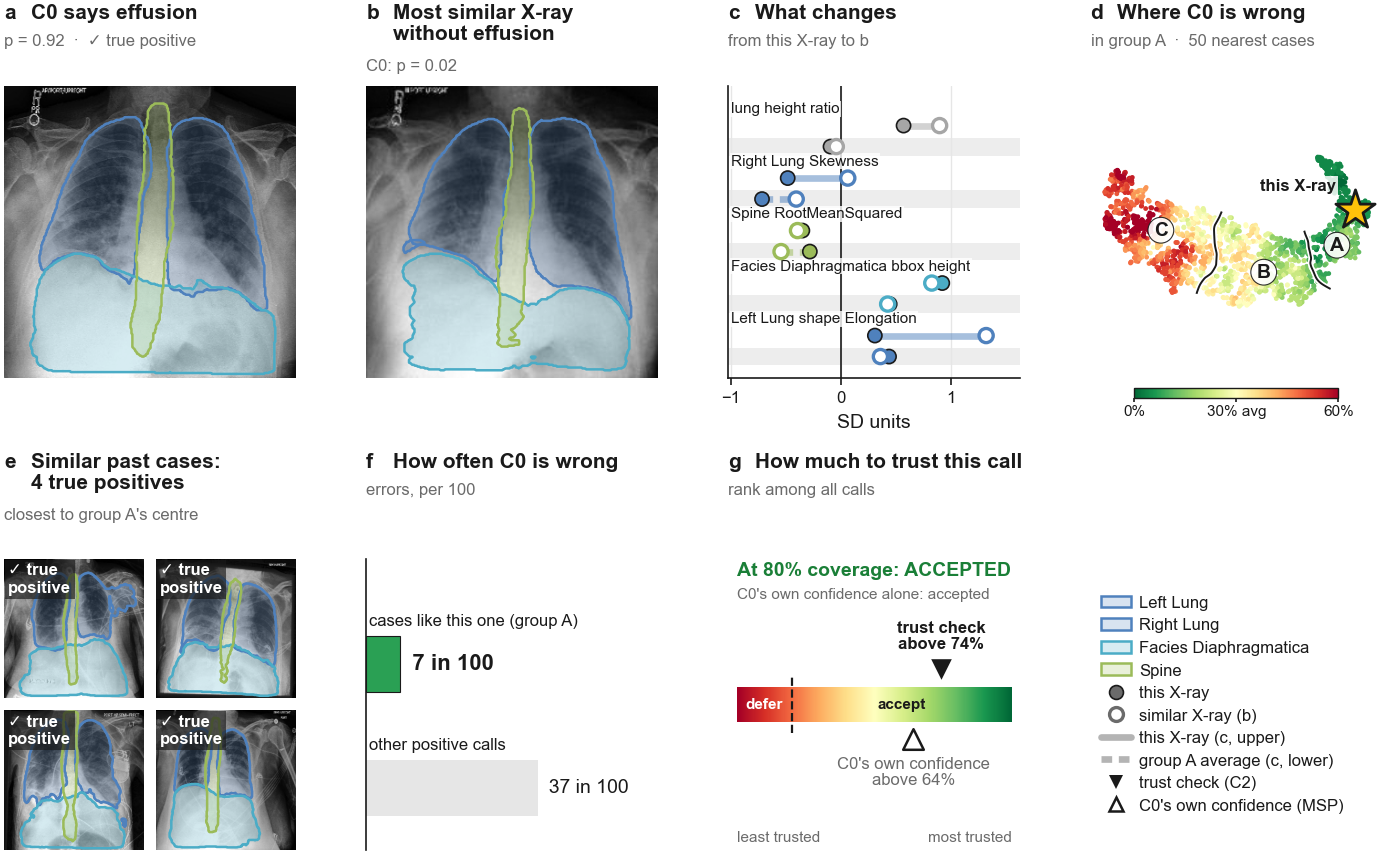

In [17]:
# A reliable case: lowest-error group, C0 was right, clearly on the accept side of the
# global COVERAGE cut (set once, in the case-card cell).
CASE_SIDE = 1            # 0 = C0 said negative, 1 = C0 said positive
case_card(CASE_SIDE, pick_case(CASE_SIDE, "A", "correct", c2=None, c2_cut="accept"))


73 candidates


,clearness,profile gap,outcome,C2 rank,MSP rank,path
17038,6.825,0.657,FP,0.079,0.001,CheXpert-v1.0-small/train/patient14831/study2/...
17302,6.657,0.738,FP,0.096,0.051,CheXpert-v1.0-small/train/patient18599/study40...
16986,6.167,0.614,FP,0.083,0.008,CheXpert-v1.0-small/train/patient14243/study2/...
18575,5.208,0.757,FP,0.088,0.007,CheXpert-v1.0-small/train/patient36155/study1/...
18848,5.157,0.686,FP,0.101,0.156,CheXpert-v1.0-small/train/patient38888/study5/...


C0 says effusion (p = 0.39)  →  counterfactual p = 0.01  →  group C  →  C2 score lower than 92% of all calls
Cases like this one: 47 in 100 effusion calls are false positives, vs 18 in 100 for other positive calls
Classifier = C0 (FP). b = counterfactual. g: ▼ C2 percentile 8%, △ MSP percentile 0%, among all calls
At 80% coverage (the 20% least trusted calls in its fold deferred): C2 deferred, MSP deferred
This global cut defers 40% of positive calls with C2 (33% with MSP), not a fixed 20%

saved: figures/xai/effusion/effusion_diffusion_hml_sub20k_case_positive_groupC_FP_cov80_row17038.{pdf,png,txt}


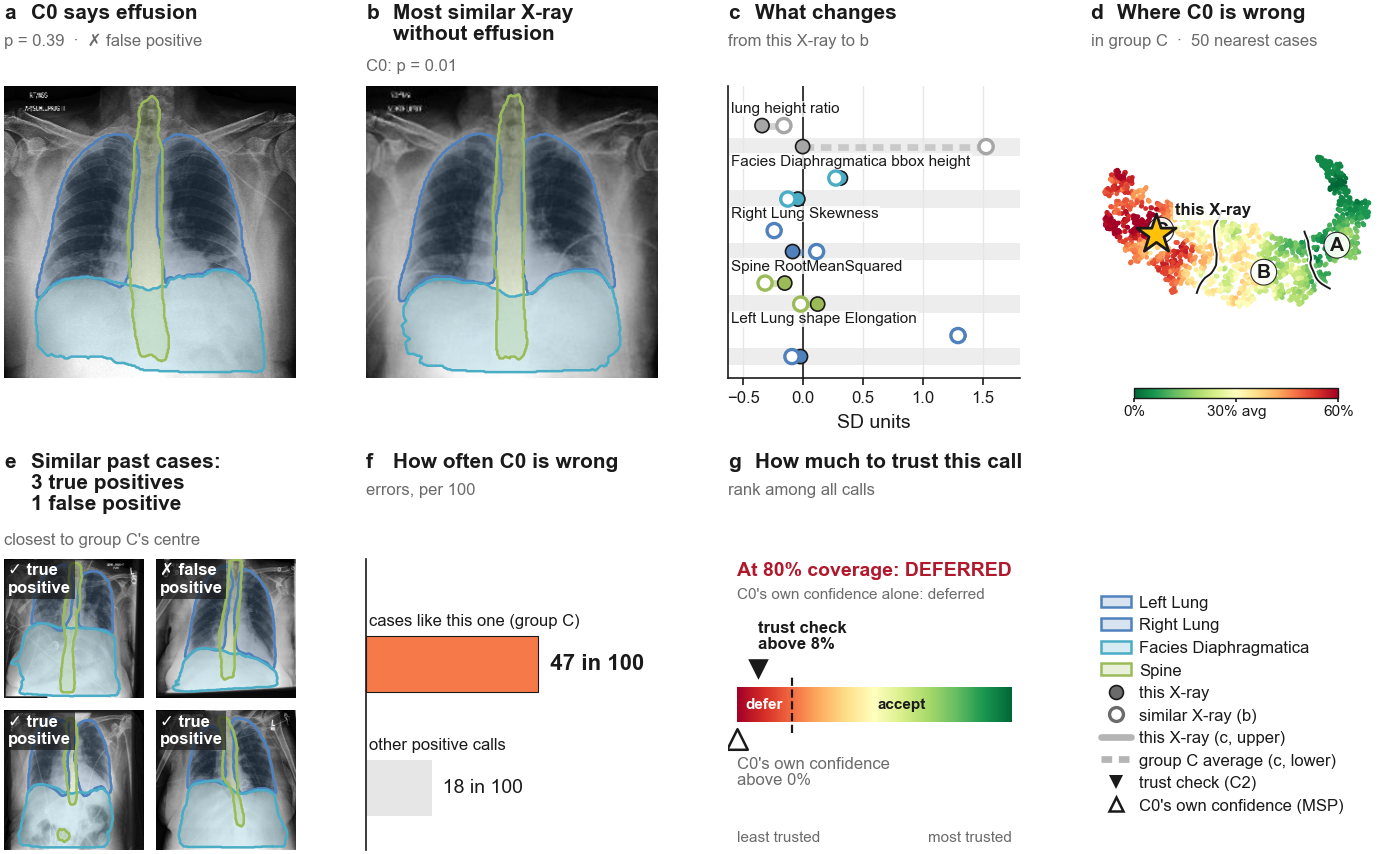

In [18]:
# A risky case: highest-error group, C0 was wrong, and C2 defers it at the global COVERAGE cut.
# MSP is not filtered on: the trust meter shows wherever MSP puts it.
CASE_SIDE = 1            # 0 = C0 said negative, 1 = C0 said positive
case_card(CASE_SIDE, pick_case(CASE_SIDE, LETTERS[N_CLUSTERS - 1], "wrong",
                              c2=None, c2_cut="defer"))


94 candidates


,clearness,profile gap,outcome,C2 rank,MSP rank,path
18379,9.870,0.784,TN,0.964,0.915,CheXpert-v1.0-small/train/patient34482/study7/...
18222,7.660,0.559,TN,0.957,0.952,CheXpert-v1.0-small/train/patient32202/study1/...
19257,7.508,0.651,TN,0.951,0.915,CheXpert-v1.0-small/train/patient44518/study1/...
16664,5.849,0.611,TN,0.974,0.993,CheXpert-v1.0-small/train/patient10178/study3/...
16421,5.712,0.687,TN,0.972,0.952,CheXpert-v1.0-small/train/patient07318/study2/...


C0 says no effusion (p = 0.01)  →  counterfactual p = 0.88  →  group A  →  C2 score higher than 96% of all calls
Cases like this one: 1 in 100 no-effusion calls are false negatives, vs 14 in 100 for other negative calls
Classifier = C0 (TN). b = counterfactual. g: ▼ C2 percentile 96%, △ MSP percentile 91%, among all calls
At 80% coverage (the 20% least trusted calls in its fold deferred): C2 accepted, MSP accepted
This global cut defers 0% of negative calls with C2 (6% with MSP), not a fixed 20%

saved: figures/xai/effusion/effusion_diffusion_hml_sub20k_case_negative_groupA_TN_cov80_row18379.{pdf,png,txt}


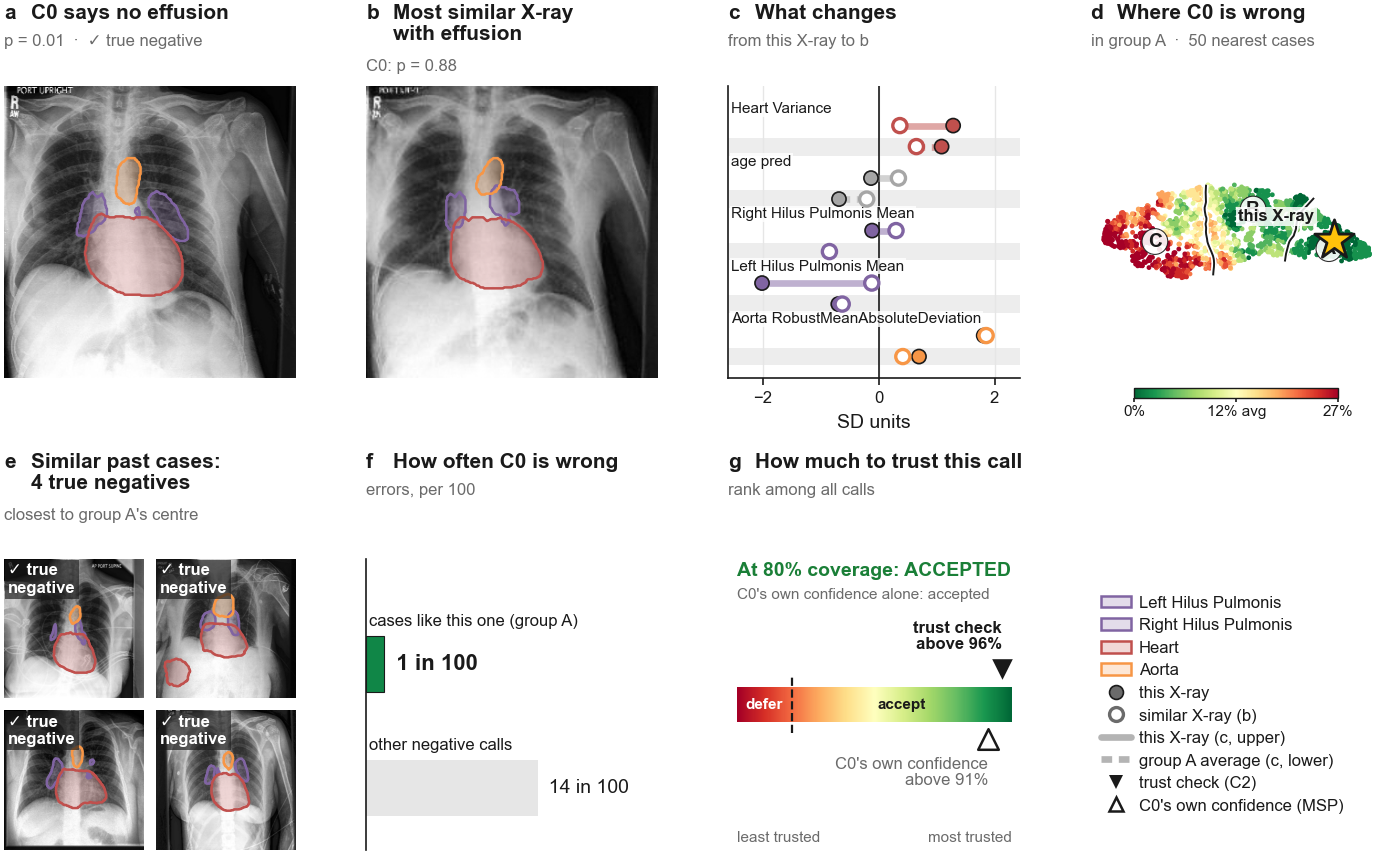

In [19]:
# A reliable negative case: lowest-error group, C0 was right, clearly on the accept side of
# the global COVERAGE cut.
CASE_SIDE = 0            # 0 = C0 said negative, 1 = C0 said positive
case_card(CASE_SIDE, pick_case(CASE_SIDE, "A", "correct", c2=None, c2_cut="accept"))



40 candidates


,clearness,profile gap,outcome,C2 rank,MSP rank,path
19989,6.663,0.480,FN,0.414,0.401,CheXpert-v1.0-small/train/patient64152/study1/...
18333,5.940,0.513,FN,0.446,0.416,CheXpert-v1.0-small/train/patient33732/study1/...
18213,5.216,0.628,FN,0.361,0.559,CheXpert-v1.0-small/train/patient32068/study2/...
19034,5.047,0.601,FN,0.406,0.136,CheXpert-v1.0-small/train/patient40950/study2/...
17167,4.984,0.651,FN,0.384,0.334,CheXpert-v1.0-small/train/patient16776/study3/...


C0 says no effusion (p = 0.20)  →  counterfactual p = 0.87  →  group C  →  C2 score lower than 59% of all calls
Cases like this one: 21 in 100 no-effusion calls are false negatives, vs 5 in 100 for other negative calls
Classifier = C0 (FN). b = counterfactual. g: ▼ C2 percentile 41%, △ MSP percentile 40%, among all calls
At 80% coverage (the 20% least trusted calls in its fold deferred): C2 accepted, MSP accepted
This global cut defers 0% of negative calls with C2 (6% with MSP), not a fixed 20%

saved: figures/xai/effusion/effusion_diffusion_hml_sub20k_case_negative_groupC_FN_cov80_row19989.{pdf,png,txt}


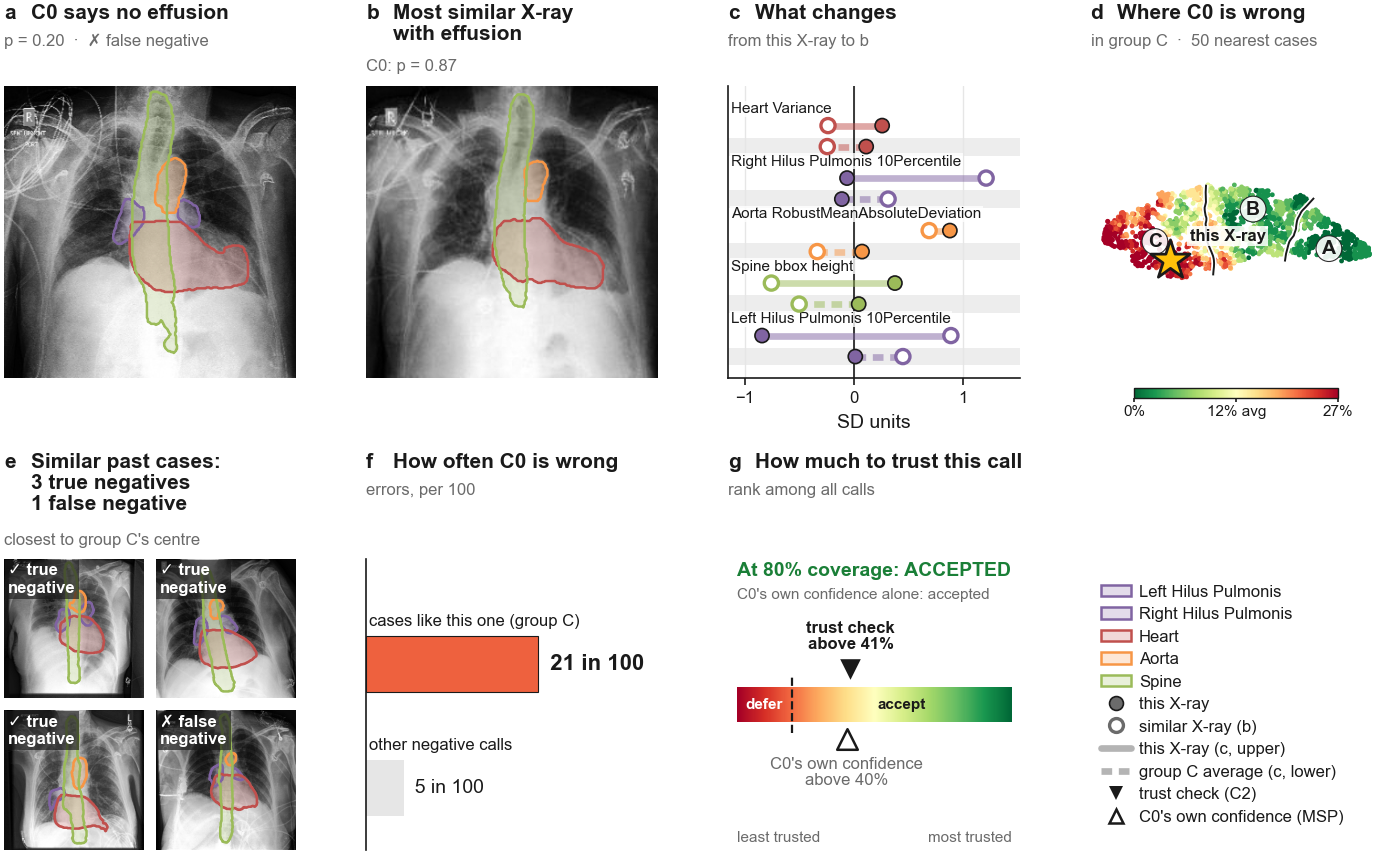

In [20]:
# A risky negative case: highest-error group, C0 missed the disease (false negative). No cut
# filter: when the global COVERAGE cut does not reach the negative calls (cardiomegaly at 80%:
# 0% of them deferred), a deferred false negative does not exist, and the card honestly shows
# even this missed case accepted. Add c2_cut="defer" for diseases where the cut does reach them.
CASE_SIDE = 0            # 0 = C0 said negative, 1 = C0 said positive
case_card(CASE_SIDE, pick_case(CASE_SIDE, LETTERS[N_CLUSTERS - 1], "wrong", c2=None))


## Checks

Diagnostics for choosing cases, not a figure: how C2 and MSP rank and defer each side under the
global per-fold ranking, how many group-A correct calls survive each `pick_case` filter, and the
share of each side deferred at a range of coverages.


In [21]:
# How C2 / MSP rank the calls of each side under the global (per-fold) ranking, and how many
# group-A correct calls survive each pick_case filter.
thr = 1 - COVERAGE
for p, side in [(1, "positive"), (0, "negative")]:
    r = pred == p
    print(f"{side} calls: median C2 rank {data.loc[r, 'c2_rank'].median():.2f}, "
          f"deferred by C2 {(data.loc[r, 'c2_rank'] < thr).mean():.0%}, "
          f"by MSP {(data.loc[r, 'msp_rank'] < thr).mean():.0%}, "
          f"in C2's global top third {(data.loc[r, 'c2_rank'] >= 2 / 3).mean():.1%}")

k    = N_CLUSTERS - LETTERS.index("A")
in_k = cluster[1].index[(cluster[1] == k).values]
cand = in_k[held_out.loc[in_k].values]
cand = cand[data.loc[cand, "correct"].values == 1]
print(f"\ngroup A, positive, held-out, correct: {len(cand)}")
print(f"  + C2 rank >= 2/3 (c2='agree'):        {(data.loc[cand, 'c2_rank'] >= 2 / 3).sum()}")
print(f"  + C2 rank >= {thr + 0.05:.2f} (c2_cut='accept'): {(data.loc[cand, 'c2_rank'] >= thr + 0.05).sum()}")

# Share of each side deferred by C2 and MSP at a range of coverages (global per-fold ranks):
# shows the coverage below which the cut starts to reach the negative calls.
rows = []
for cov in [0.95, 0.90, 0.85, 0.80, 0.75, 0.70, 0.65, 0.60, 0.50]:
    thr = 1 - cov
    row = {"coverage": f"{cov:.0%}"}
    for p, side in [(1, "pos"), (0, "neg")]:
        r = pred == p
        row[f"C2 defers {side}"]  = f"{(data.loc[r, 'c2_rank'] < thr).mean():.0%}"
        row[f"MSP defers {side}"] = f"{(data.loc[r, 'msp_rank'] < thr).mean():.0%}"
    rows.append(row)
display(pd.DataFrame(rows).set_index("coverage"))


positive calls: median C2 rank 0.29, deferred by C2 38%, by MSP 33%, in C2's global top third 16.1%
negative calls: median C2 rank 0.68, deferred by C2 2%, by MSP 7%, in C2's global top third 51.1%

group A, positive, held-out, correct: 236
  + C2 rank >= 2/3 (c2='agree'):        164
  + C2 rank >= 0.25 (c2_cut='accept'): 236


,C2 defers pos,MSP defers pos,C2 defers neg,MSP defers neg
coverage,,,,
95%,10%,10%,0%,0%
90%,19%,20%,0%,0%
85%,29%,28%,1%,2%
80%,38%,33%,2%,7%
75%,45%,39%,4%,11%
70%,51%,44%,9%,15%
65%,55%,50%,14%,20%
60%,59%,55%,20%,24%
50%,68%,67%,31%,33%
